In [50]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm

eps = 0.000001

save_tag = '7jul'

In [51]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

def mad(x):
    return np.median(np.abs(x - np.median(x)))

def rng(x):
    return x.max() - x.min()

def statistics(x):
    mean = np.mean(x)
    sd = np.std(x)
    median = np.median(x)
    q1 = np.percentile(x, 25)
    q3 = np.percentile(x, 75)
    iqr = q3 - q1
    return mean.item(), median.item(), sd.item(), iqr.item()


def remove_outlayer(x, method='3sigma', return_bin=True, thr=3):
    mean, median, sd, iqr = statistics(x)
    if method == '3sigma':
        z = (x - mean) / (sd + eps)
        binary = (z >= -thr) & (z <= thr)
        return binary if return_bin else x[binary]
    elif method == 'iqr':
        q1, q3 = np.percentile(x, [25, 75])
        binary = (x >= (q1 - thr*iqr)) &  (x <= (q3 + thr*iqr))
        return binary if return_bin else x[binary]
    else:
        print('Method not implemented')
        return None


def remove_outlayer_df(df, assay, method, thr=3):
    """
    method = ('3sigma', 'iqr')
    """
    
    binary = []
    for i in df['Plate_ID'].unique():
        x = df.loc[df['Plate_ID'] == i, assay]
        binary.extend(remove_outlayer(x, method, thr).tolist())
    binary = np.array(binary)
    df_new = df.loc[binary].copy()
    return df_new
    

def normalize(x, control, method='mean', scale=False):
    mean, median, sd, iqr = statistics(control)
    if not scale:
        sd, iqr = 1, 1
    if method == 'mean':
        return (x - mean) / sd if sd > eps else 0
    elif method == 'median':
        return (x - median) / (iqr) if iqr > eps else 0
    else:
        print('Method not implemented')
        return None


def get_delta_values(df, df_ref, assay, method):
    df_ref[f'delta_{assay}'] = None
    for i in df_ref['Plate_ID'].unique():
        x = df.loc[df['Plate_ID'] == i, assay]
        control = df_ref.loc[df_ref['Plate_ID'] == i, assay]
        
        x = normalize(x, control, method=method, scale=True)
        df.loc[df['Plate_ID'] == i, f'norm_{assay}'] = x
        
        x = normalize(control, control, method=method, scale=True)
        df_ref.loc[df_ref['Plate_ID'] == i, f'norm_{assay}'] = x

    return df, df_ref
    

def emperical_p_value(x, null, alternative='two_sided', take_abs=False):
    if take_abs:
        null = np.abs(null)
        x = np.abs(x)
    if alternative == 'greater':
        p = np.mean(x <= null)
    elif alternative == 'less':
        p = np.mean(x >= null)
    elif  alternative == 'two_sided':
        p = np.mean(x <= null | x >= null)
    else:
        print('Invalid "alternative" parameter')
    return p


def boxplot_per_plate(df, assay, protein, title='', ordered=True, save_dir=None, ylim=None):
    # Plate-id orderes: 
    # to see original order use Plate_ID
    # to see them ordered based on numbers use Plate_ID_cat
    plate_id = 'Plate_ID_cat' if ordered else 'Plate_ID'
    
    plt.figure(figsize=(20, 6))

    df = df.loc[df['Protein'] == protein].copy()
    df['Plate_ID_cat'] = df['Plate_ID_cat'].cat.remove_unused_categories()
    
    n_plate = len(df[plate_id].unique())
    plt.vlines(np.arange(0, n_plate, 2), ymin = -100, ymax = 100, colors='gray', linestyles='dashed', linewidth=0.5)
    sns.boxplot(data=df, x=plate_id, y=assay)
    
    plt.title(f'{assay} {protein}, {title}')
    plt.xticks(rotation=90, size = 5)
    plt.xlabel('Plate ID')
    plt.ylabel(' '.join(assay.split('_')))
    plt.tight_layout()
    if ylim != None:
        plt.ylim(ylim)
    if save_dir != None:
        plt.savefig(save_dir)
    plt.show()
    plt.close()


def dotplot_per_plate(df, assay, protein, ids, title='', ordered=True, save_dir=None, ylim=None):
    
    plt.figure(figsize=(20, 12))
    df = df.loc[df['Protein'] == protein].copy()
    df['Plate_ID_cat'] = df['Plate_ID_cat'].cat.remove_unused_categories()
    
    n_plate = len(df['Plate_ID_cat'].unique())
    
    df = df.loc[df['ID'].isin(ids)]
    
    plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
    plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)
    
    sns.stripplot(data=df, x='Plate_ID_cat', y=assay, hue='ID', dodge=True, jitter=True, size=4)
    
    plt.title(f'{assay} {protein}, {title}')
    plt.xticks(rotation=90, size = 5)
    plt.xlabel('Plate ID')
    plt.ylabel(' '.join(assay.split('_')))
    plt.tight_layout()
    if ylim != None:
        plt.ylim(ylim)
    if save_dir != None:
        plt.savefig(save_dir)
    plt.show()
    plt.close()


def pos_ctrl_qc(df, protein, pos_ctrl, assay, return_thr=True):
    df_tmp = df.loc[(df['Protein'] == protein) & (df['ID'] == pos_ctrl)].copy()
    x = remove_outlayer(np.array(df_tmp[assay]), method='iqr', return_bin=False, thr=1.5)
    df_tmp[f'abnormal_{pos_ctrl}_{protein}_{assay}'] = 0
    x_max, x_min = x.max(), x.min()
    df_tmp.loc[df_tmp[assay] > x_max, f'abnormal_{pos_ctrl}_{assay}'] = 1
    df_tmp.loc[df_tmp[assay] < x_min, f'abnormal_{pos_ctrl}_{assay}'] = 1
    df_qc_updated = df_tmp.groupby('Plate_ID')[f'abnormal_{pos_ctrl}_{assay}'].sum()
    return df_qc_updated, [x_min, x_max] if return_thr else df_qc_updated

In [3]:
# Read data
df_main = pd.read_excel("data/PO-ini2810_PAHcomplete_20250502.xlsx")
df_main = df_main.drop('Unnamed: 0', axis=1)
df_main.shape, len(df_main['Plate_ID'].unique())

((182688, 37), 519)

In [4]:
# Find the control compounds
# Their 'Formula' should be 'NaN'
ctlr_compounds = df_main.loc[df_main['Formula'].isna(), 'ID'].unique()
ctlr_compounds

array(['BH4', 'UCR243', 'UCR102', 'DMSO'], dtype=object)

In [5]:
# Find the proteins
df_main['Protein'].unique()

array(['PAH-WT', 'failed', 'PAH-I65T'], dtype=object)

In [6]:
df_main[(df_main['Protein'] == 'PAH-WT') & (~df_main['ID'].isin(ctlr_compounds))].shape

(80000, 37)

In [7]:
df = df_main.dropna(subset = 'Thermal_Shift').copy()
df = df.dropna(subset = 'Spectral_Shift').copy()
df = df.loc[df['Protein'] != 'failed'].copy()
df['Protein'].unique()

array(['PAH-WT', 'PAH-I65T'], dtype=object)

In [8]:
df[(df['Protein'] == 'PAH-WT') & (~df['ID'].isin(ctlr_compounds))].shape

(79800, 37)

In [9]:
# Make categorical plate ids with sorted levels based on numbers
df_plate_ids = pd.DataFrame({'ids' : df['Plate_ID'].unique()})
df_plate_ids['ids_no_letter'] = [i[1:] if i[0].isalpha() else i for i in df_plate_ids['ids']]
df_plate_ids = df_plate_ids.sort_values('ids_no_letter')
df_plate = df_plate_ids['ids']
df['Plate_ID_cat'] = pd.Categorical(df['Plate_ID'], categories=df_plate, ordered=True)

In [10]:
# define df control (DMSO) and other
ctrl_id = 'DMSO'
df_ctrl = df.loc[df['ID'] == ctrl_id].copy()   # always: negtive control (DMSO)
df_other = df.loc[df['ID'] != ctrl_id].copy()

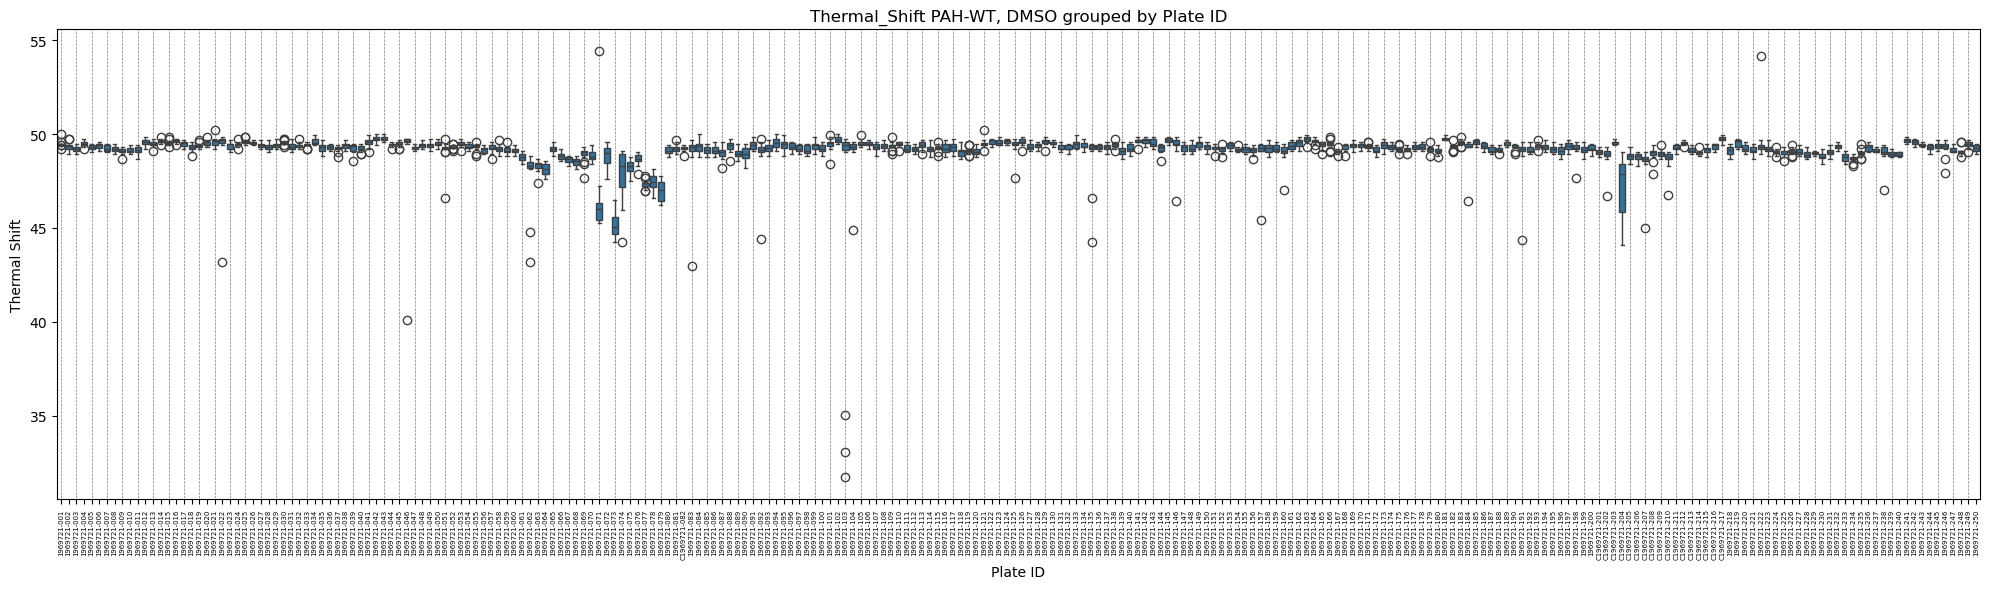

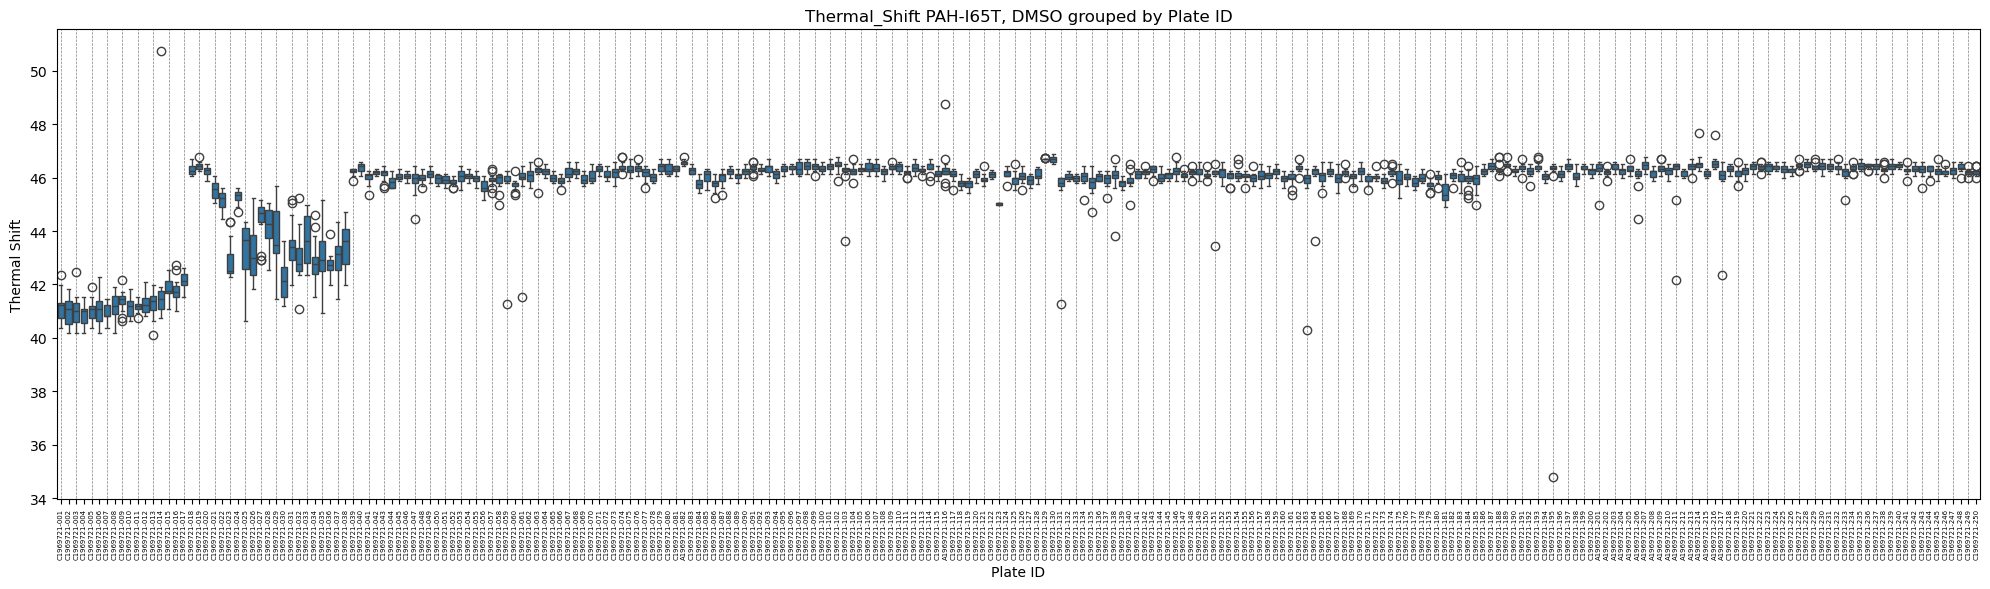

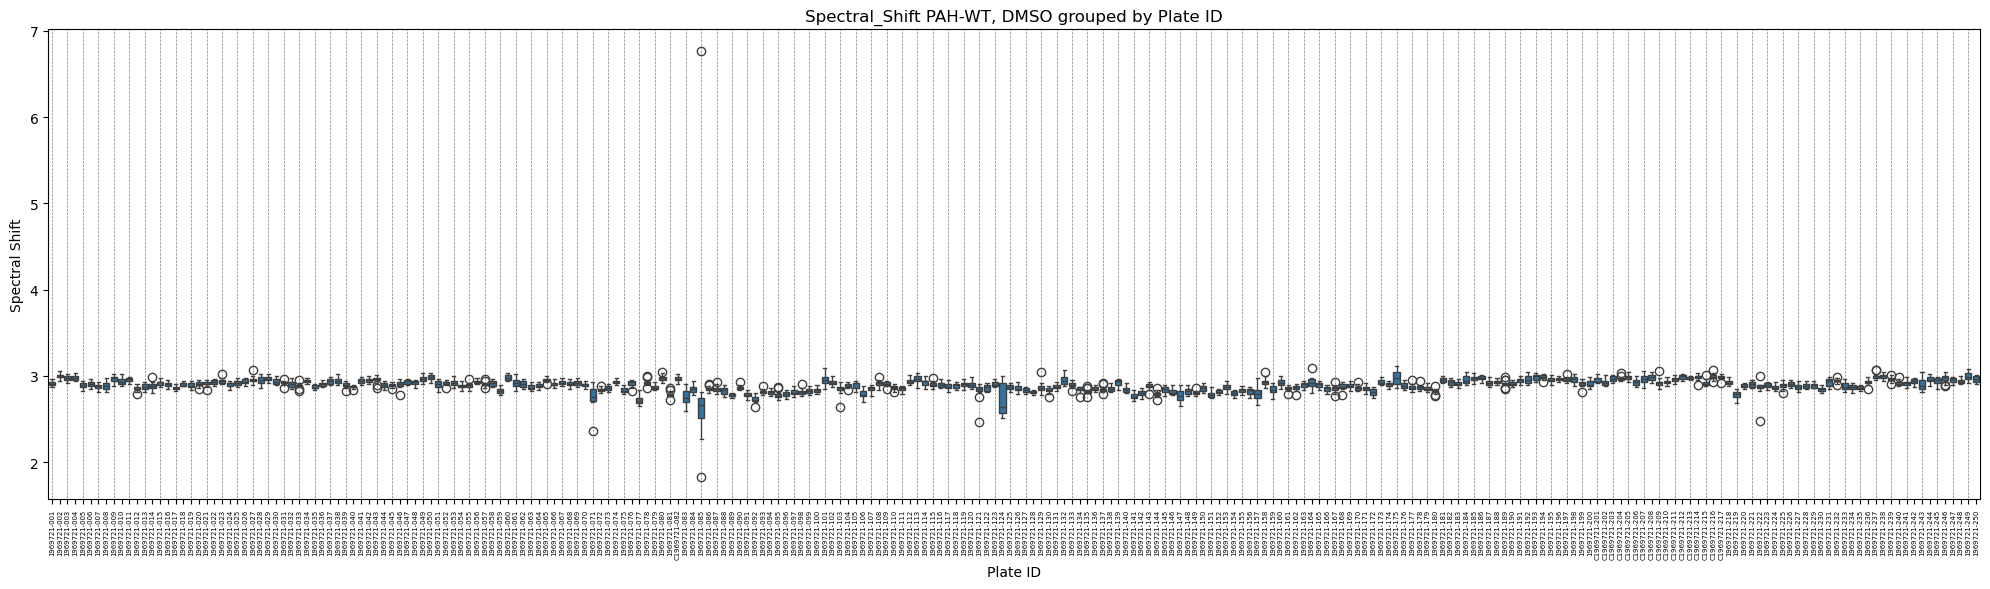

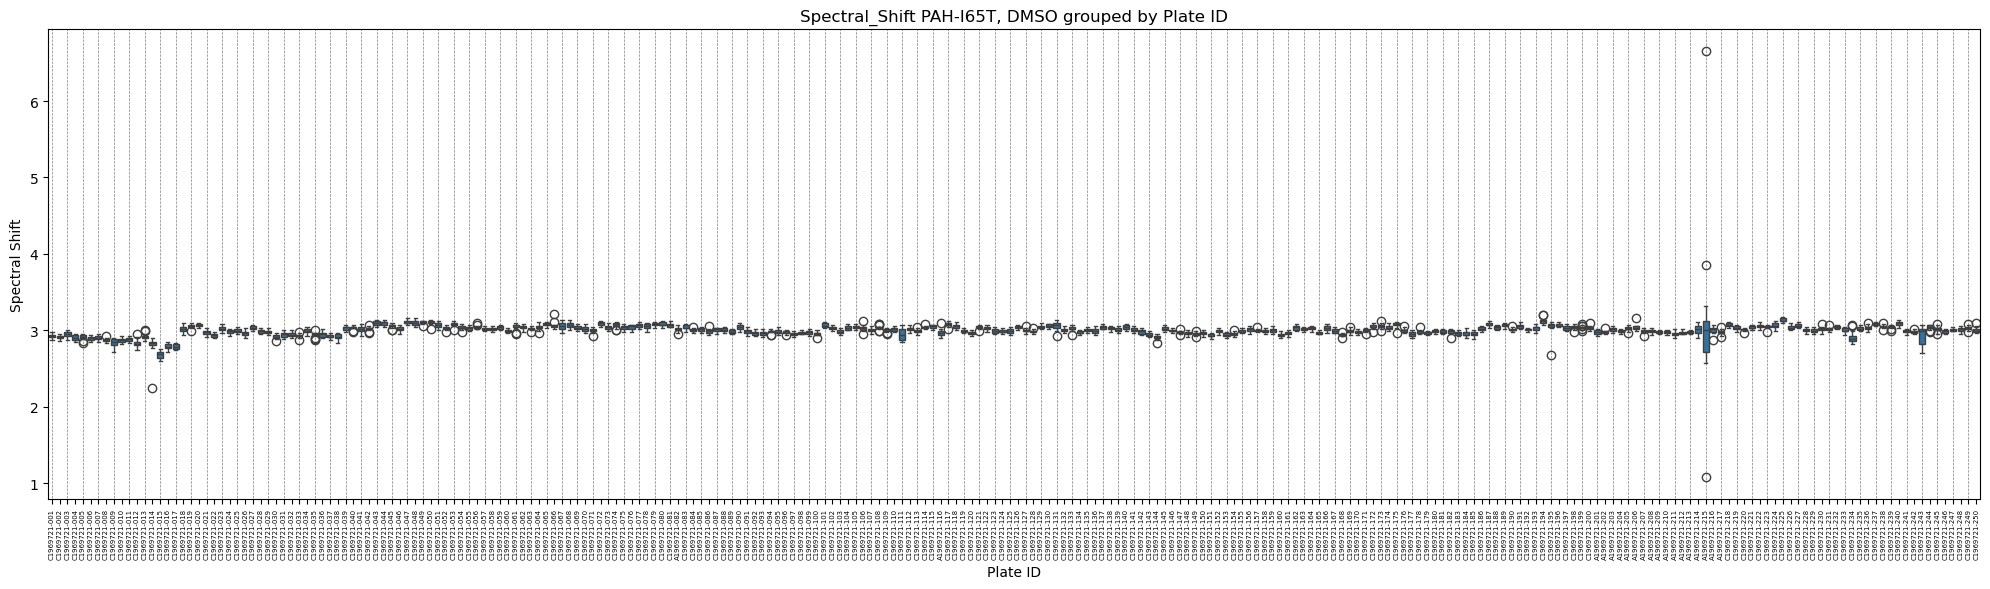

In [11]:
# Plot before outlier removal

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

In [12]:
# Get QC initial table
df_qc = (
    df_ctrl
    .groupby('Plate_ID_cat', observed=True)
    .agg({
        'Protein': 'first',
        'Thermal_Shift': ['median', iqr],
        'Spectral_Shift': ['median', iqr],
        'Fluorescence_at_25' : ['median', iqr]
    })
)
df_qc.columns = ['Protein', 'TSA_median', 'TSA_iqr', 'SpSh_median', 'SpSh_iqr', 'fl25_median', 'fl25_iqr']
df_qc.head()

,Protein,TSA_median,TSA_iqr,SpSh_median,SpSh_iqr,fl25_median,fl25_iqr
Plate_ID_cat,,,,,,,
1969721-001,PAH-WT,49.4840,0.000000,2.903465,0.031402,-32414.554826,2734.591900
C1969721-001,PAH-I65T,41.2325,0.563625,2.919414,0.030101,-102997.211915,12549.485420
C1969721-002,PAH-I65T,41.0972,0.856700,2.916621,0.033232,-96374.812378,10337.838590
1969721-002,PAH-WT,49.3487,0.180400,3.001054,0.034008,-27865.316910,1905.986941
1969721-003,PAH-WT,49.2134,0.180400,2.976828,0.049121,-29299.307264,2267.008084


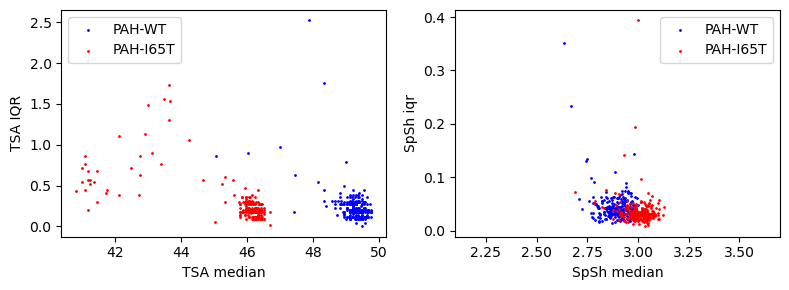

In [13]:
# Look at each plate

fig, ax = plt.subplots(1, 2, figsize=(8, 3))

# First subplot (TSA)
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'TSA_iqr'],
              s=1, color='blue', label='PAH-WT')
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'TSA_iqr'],
              s=1, color='red', label='PAH-I65T')
ax[0].set_xlabel('TSA median')
ax[0].set_ylabel('TSA IQR')
ax[0].legend()

# Second subplot (SpSh)
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'SpSh_iqr'],
              s=1, color='blue', label='PAH-WT')
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'SpSh_iqr'],
              s=1, color='red', label='PAH-I65T')
ax[1].set_xlabel('SpSh median')
ax[1].set_ylabel('SpSh iqr')
ax[1].legend()
ax[1].set_xlim([2.1, 3.7])
plt.tight_layout()
plt.show()


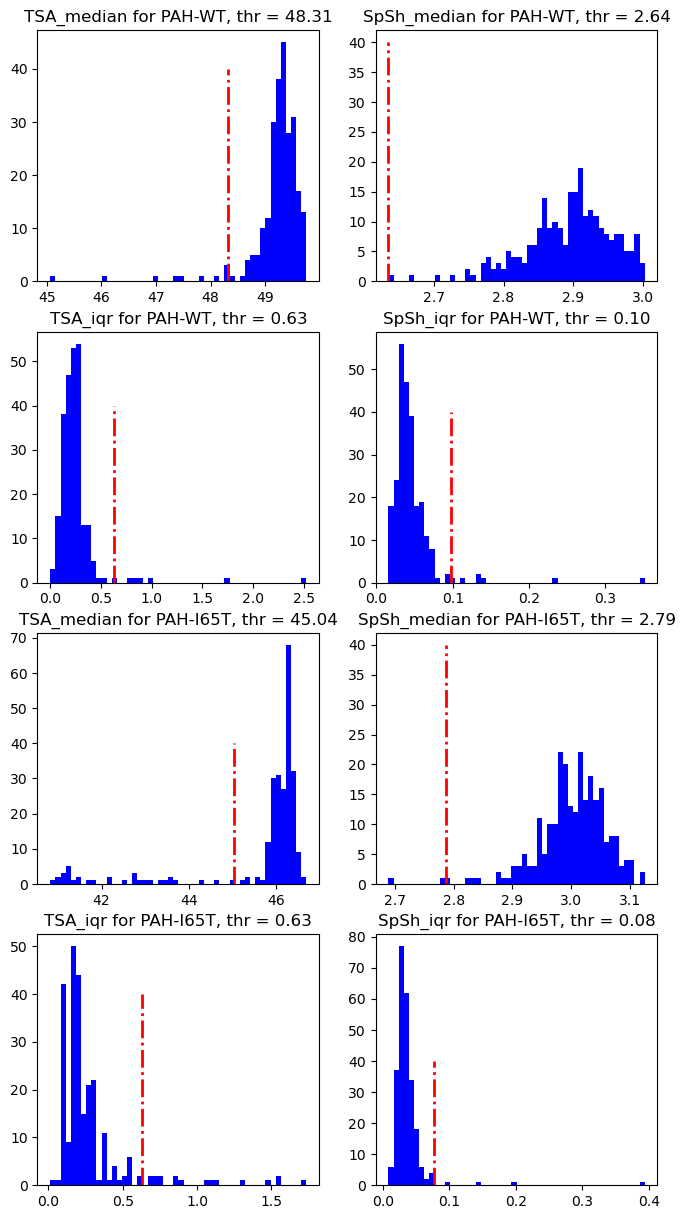

In [14]:
# Remove plates based on mean and IQR method
plate_outlier = []

fig, ax = plt.subplots(4, 2, figsize=(8, 15))
ax = ax.flatten()
th_set = {}

i = 0
for prot in ['PAH-WT', 'PAH-I65T']:
    for col in ['TSA_median', 'SpSh_median', 'TSA_iqr', 'SpSh_iqr']:
        df_tmp = df_qc.loc[df_qc['Protein'] == prot].copy()
        x = remove_outlayer(np.array(df_tmp[col]), method='iqr', return_bin=False)

        if col.split('_')[1] in ['median', 'mean']:
            thr = x.min()
            plate_outlier.extend(list(df_tmp.loc[df_tmp[col] < thr].index))
        else:
            thr = x.max()
            plate_outlier.extend(list(df_tmp.loc[df_tmp[col] > thr].index))
            # thr = x.min()
            # plate_outlier.extend(list(df_tmp.loc[df_tmp[col] < thr].index))

        th_set[f'{col}_{prot}'] = thr
        ax[i].hist(df_tmp[col], 50, color='blue');
        ax[i].vlines(thr, ymin=0, ymax=40, colors='red', linestyles='-.', linewidth=2)
        ax[i].set_title(f'{col} for {prot}, thr = {thr:.2f}');
        i += 1

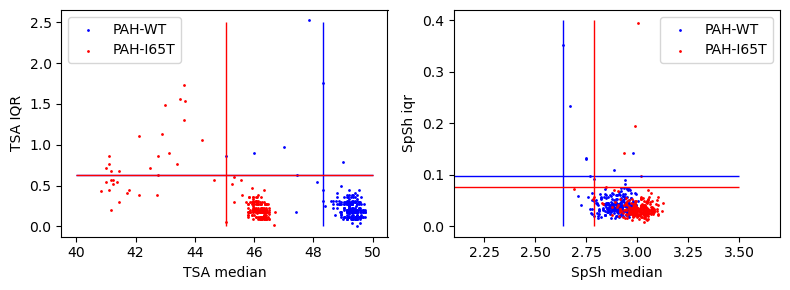

In [15]:
# Look at each plate

fig, ax = plt.subplots(1, 2, figsize=(8, 3))

# First subplot (TSA)
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'TSA_iqr'],
              s=1, color='blue', label='PAH-WT')
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'TSA_iqr'],
              s=1, color='red', label='PAH-I65T')

ax[0].vlines(th_set[f'TSA_median_PAH-WT'], ymin=0, ymax=2.5, colors='blue', linewidth=1)
ax[0].hlines(th_set[f'TSA_iqr_PAH-WT'], xmin=40, xmax=50, colors='blue', linewidth=1)
ax[0].vlines(th_set[f'TSA_median_PAH-I65T'], ymin=0, ymax=2.5, colors='red', linewidth=1)
ax[0].hlines(th_set[f'TSA_iqr_PAH-I65T'], xmin=40, xmax=50, colors='red', linewidth=1)

ax[0].set_xlabel('TSA median')
ax[0].set_ylabel('TSA IQR')
ax[0].legend()

# Second subplot (SpSh)
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'SpSh_iqr'],
              s=1, color='blue', label='PAH-WT')
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'SpSh_iqr'],
              s=1, color='red', label='PAH-I65T')

ax[1].vlines(th_set[f'SpSh_median_PAH-WT'], ymin=0, ymax=.4, colors='blue', linewidth=1)
ax[1].hlines(th_set[f'SpSh_iqr_PAH-WT'], xmin=2, xmax=3.5, colors='blue', linewidth=1)
ax[1].vlines(th_set[f'SpSh_median_PAH-I65T'], ymin=0, ymax=.4, colors='red', linewidth=1)
ax[1].hlines(th_set[f'SpSh_iqr_PAH-I65T'], xmin=2, xmax=3.5, colors='red', linewidth=1)

ax[1].set_xlabel('SpSh median')
ax[1].set_ylabel('SpSh iqr')
ax[1].legend()
ax[1].set_xlim([2.1, 3.7])

plt.tight_layout()
plt.show()


In [16]:
df_qc['out_of_distribution'] = 'no'
df_qc.loc[df_qc.index.isin(plate_outlier), 'out_of_distribution'] = 'yes'
df_qc

,Protein,TSA_median,TSA_iqr,SpSh_median,SpSh_iqr,fl25_median,fl25_iqr,out_of_distribution
Plate_ID_cat,,,,,,,,
1969721-001,PAH-WT,49.48400,0.000000,2.903465,0.031402,-32414.554826,2734.591900,no
C1969721-001,PAH-I65T,41.23250,0.563625,2.919414,0.030101,-102997.211915,12549.485420,yes
C1969721-002,PAH-I65T,41.09720,0.856700,2.916621,0.033232,-96374.812378,10337.838590,yes
1969721-002,PAH-WT,49.34870,0.180400,3.001054,0.034008,-27865.316910,1905.986941,no
1969721-003,PAH-WT,49.21340,0.180400,2.976828,0.049121,-29299.307264,2267.008084,no
...,...,...,...,...,...,...,...,...
1969721-248,PAH-WT,49.07815,0.112650,2.928895,0.032737,-82515.676513,7068.435198,no
C1969721-249,PAH-I65T,46.19240,0.090200,3.029309,0.023824,-53588.817146,4181.566233,no
1969721-249,PAH-WT,49.48400,0.202850,2.986527,0.064130,-74793.274132,10947.396269,no


In [17]:
plate_outlier = list(set(plate_outlier))
len(plate_outlier)

50

In [18]:
# Remove outlier plates from the original df
df_outlier_removed = df.loc[~df['Plate_ID'].isin(plate_outlier)].copy()
df_outlier_removed.shape

(153690, 38)

In [19]:
# Get df_ctrl and df_other again
ctrl_id = 'DMSO'
df_ctrl = df_outlier_removed.loc[df_outlier_removed['ID'] == ctrl_id].copy()
df_other = df_outlier_removed.loc[df_outlier_removed['ID'] != ctrl_id].copy()

In [20]:
# Remove DMSO outlayer

print(df_ctrl.shape)

df_ctrl = remove_outlayer_df(df_ctrl, 
                             assay = 'Thermal_Shift', 
                             method = 'iqr'
                            )
df_ctrl = remove_outlayer_df(df_ctrl, 
                             assay = 'Spectral_Shift', 
                             method = 'iqr'
                            )
print(df_ctrl.shape)

# Which one? 
# remove outlier plates, and then remove dmso smaples or the other way around?
# The first scenario is more strict. So, let's move with it.

(7190, 38)
(7077, 38)


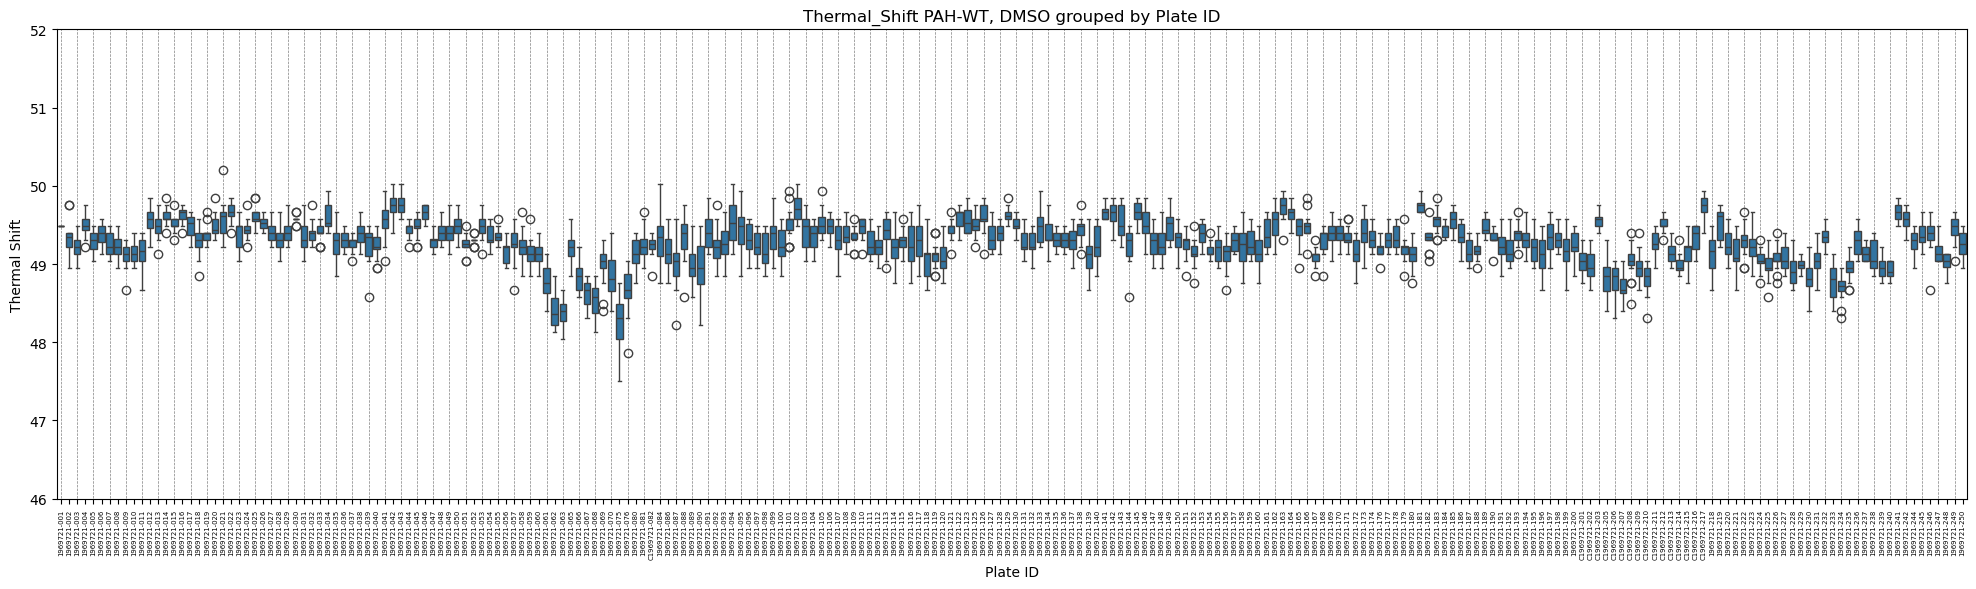

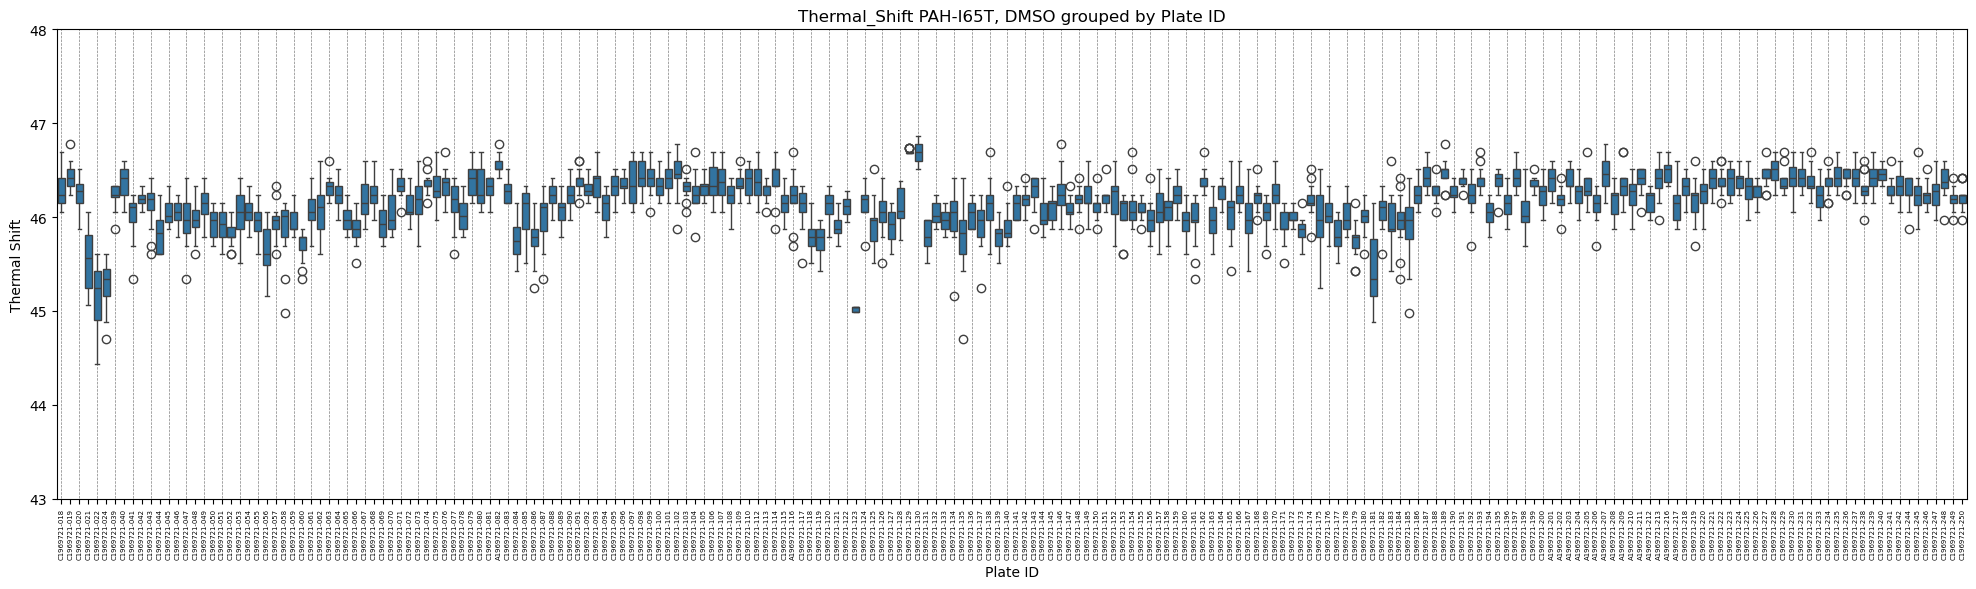

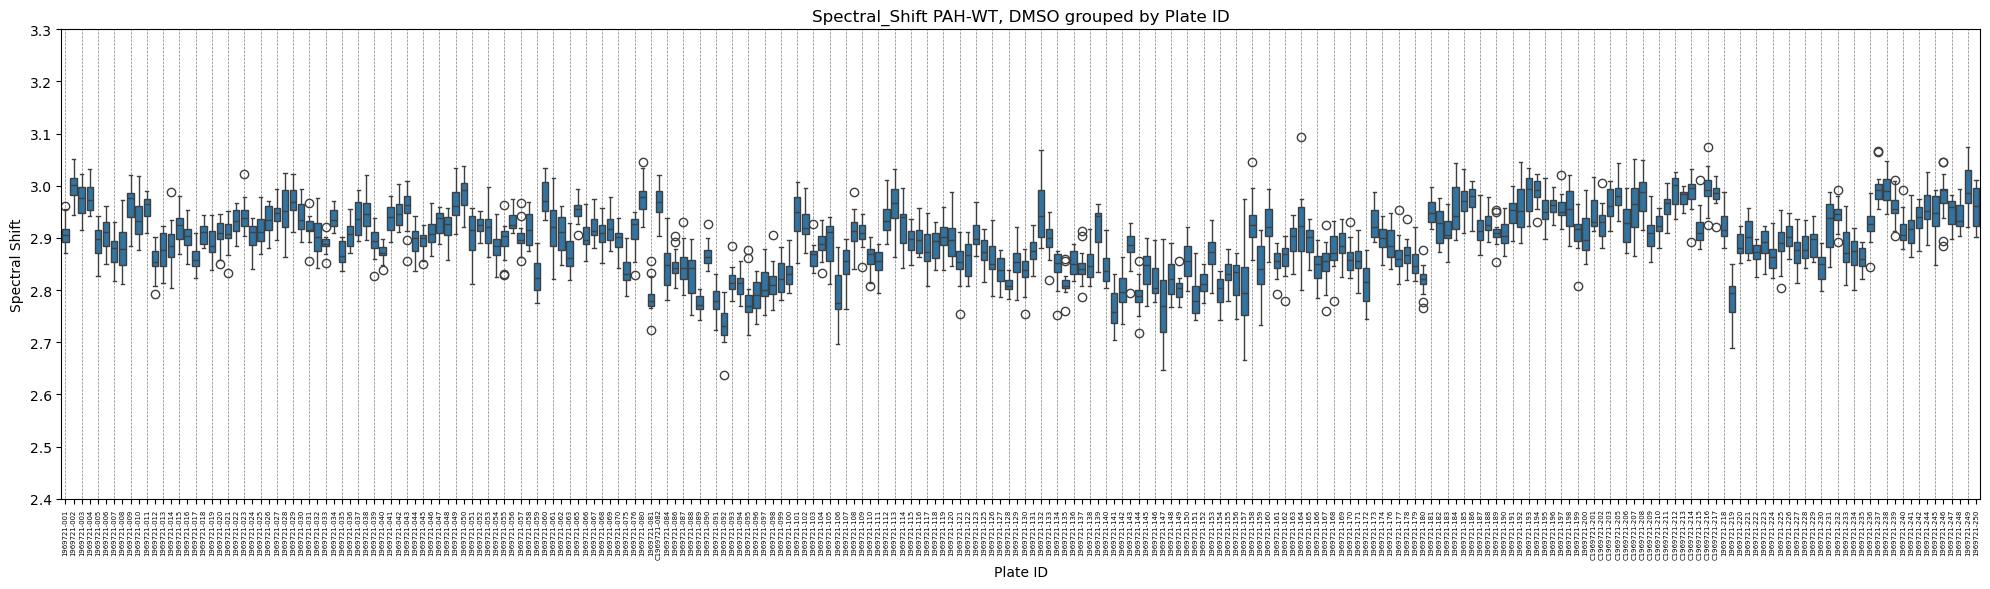

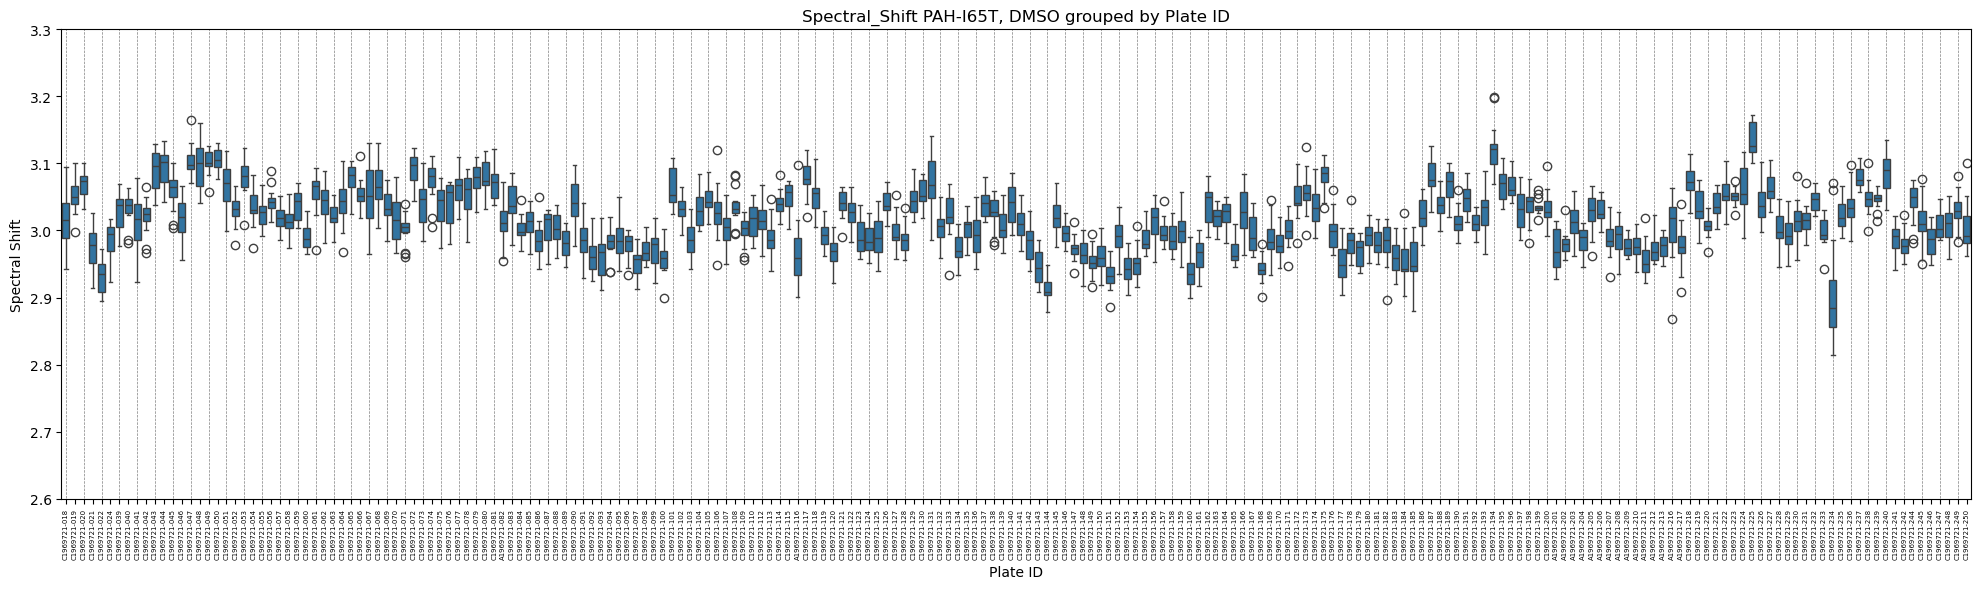

In [21]:
# Plot after outlier removal

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[46, 52]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[43, 48]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[2.4, 3.3]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[2.6, 3.3]
                 )

In [22]:
df_ctrl.head(20)

,ID,Cxsmiles,Formula,MW,Purity,PO,Salt smiles,Salt_name,Salt_ratio,MW_salt,...,SpSh_Warning,DMSO_SpSh_median,DMSO_SpSh_mean,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37,Plate_ID_cat
66,DMSO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN,1969721-001
88,DMSO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN,1969721-001
89,DMSO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN,1969721-001
133,DMSO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN,1969721-001
177,DMSO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN,1969721-001
221,DMSO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN,1969721-001
243,DMSO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN,1969721-001
265,DMSO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN,1969721-001
287,DMSO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN,1969721-001
309,DMSO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN,1969721-001


In [23]:
(df_ctrl.loc[df_ctrl['Plate_ID_cat'] == '1969721-002', 'Thermal_Shift'], 
 df_ctrl.loc[df_ctrl['Plate_ID_cat'] == '1969721-003', 'Thermal_Shift'])

(418    49.7545
 419    49.2134
 440    49.2134
 441    49.3938
 462    48.9429
 463    49.3938
 485    49.3938
 507    49.2134
 529    49.2134
 551    49.3938
 573    49.3938
 595    49.3938
 617    49.2134
 639    49.3036
 661    49.7545
 683    49.3036
 Name: Thermal_Shift, dtype: float64,
 770     49.2134
 771     49.0331
 792     49.4840
 793     49.2134
 814     49.3036
 815     49.2134
 837     49.1232
 859     49.3036
 881     49.3036
 903     49.1232
 925     48.9429
 947     49.2134
 969     49.1232
 991     49.2134
 1013    49.3938
 1035    49.0331
 Name: Thermal_Shift, dtype: float64)

(np.float64(0.3341527172940141), np.float64(0.07770587815303272))

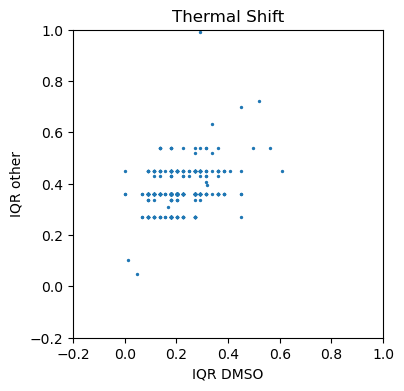

In [41]:
iqr_other = df_other.groupby('Plate_ID')['Thermal_Shift'].agg(iqr)
iqr_crtl = df_ctrl.groupby('Plate_ID')['Thermal_Shift'].agg(iqr)
iqr_other = np.array(iqr_other)
iqr_crtl = np.array(iqr_crtl)

plt.subplots(figsize=(4, 4))
plt.scatter(iqr_crtl, iqr_other, s=2)
plt.ylabel('IQR other')
plt.xlabel('IQR DMSO')
plt.title('Thermal Shift')
plt.xlim([-.2, 1])
plt.ylim([-.2, 1])

np.corrcoef(iqr_other, iqr_crtl)[0, 1], np.std(iqr_other)

(np.float64(0.4424840580305848), np.float64(0.011956673249566346))

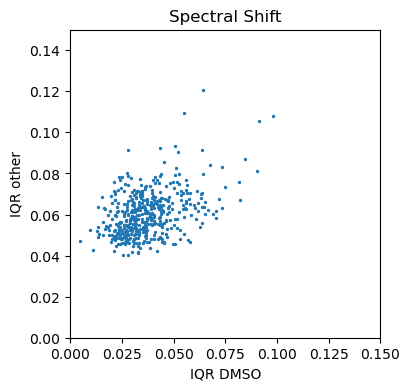

In [43]:
iqr_other = df_other.groupby('Plate_ID')['Spectral_Shift'].agg(iqr)
iqr_crtl = df_ctrl.groupby('Plate_ID')['Spectral_Shift'].agg(iqr)
iqr_other = np.array(iqr_other)
iqr_crtl = np.array(iqr_crtl)

plt.subplots(figsize=(4, 4))
plt.scatter(iqr_crtl, iqr_other, s=2)
plt.ylabel('IQR other')
plt.xlabel('IQR DMSO')
plt.title('Spectral Shift')
plt.xlim([0, .15])
plt.ylim([0, .15])

np.corrcoef(iqr_other, iqr_crtl)[0, 1], np.std(iqr_other)

In [26]:
# Delta values generation (subtract DMSO median)

# Delta Tm
df_other, df_ctrl = get_delta_values(df_other,
                                     df_ctrl,
                                     assay = 'Thermal_Shift',
                                     method = 'median'
                                    )
# Delta SpSh
df_other, df_ctrl = get_delta_values(df_other,
                                     df_ctrl,
                                     assay = 'Spectral_Shift',
                                     method = 'median'
                                    )

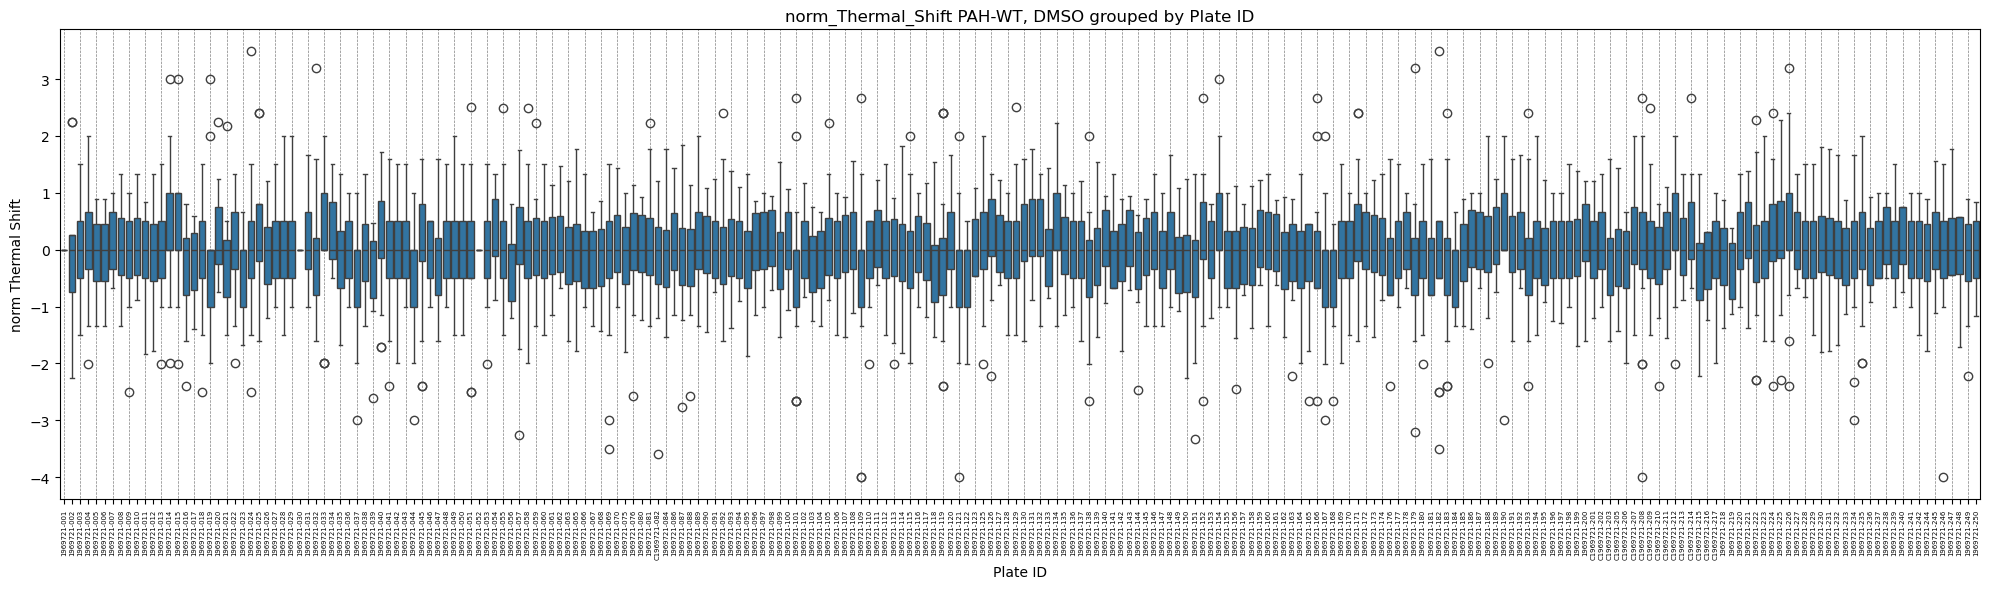

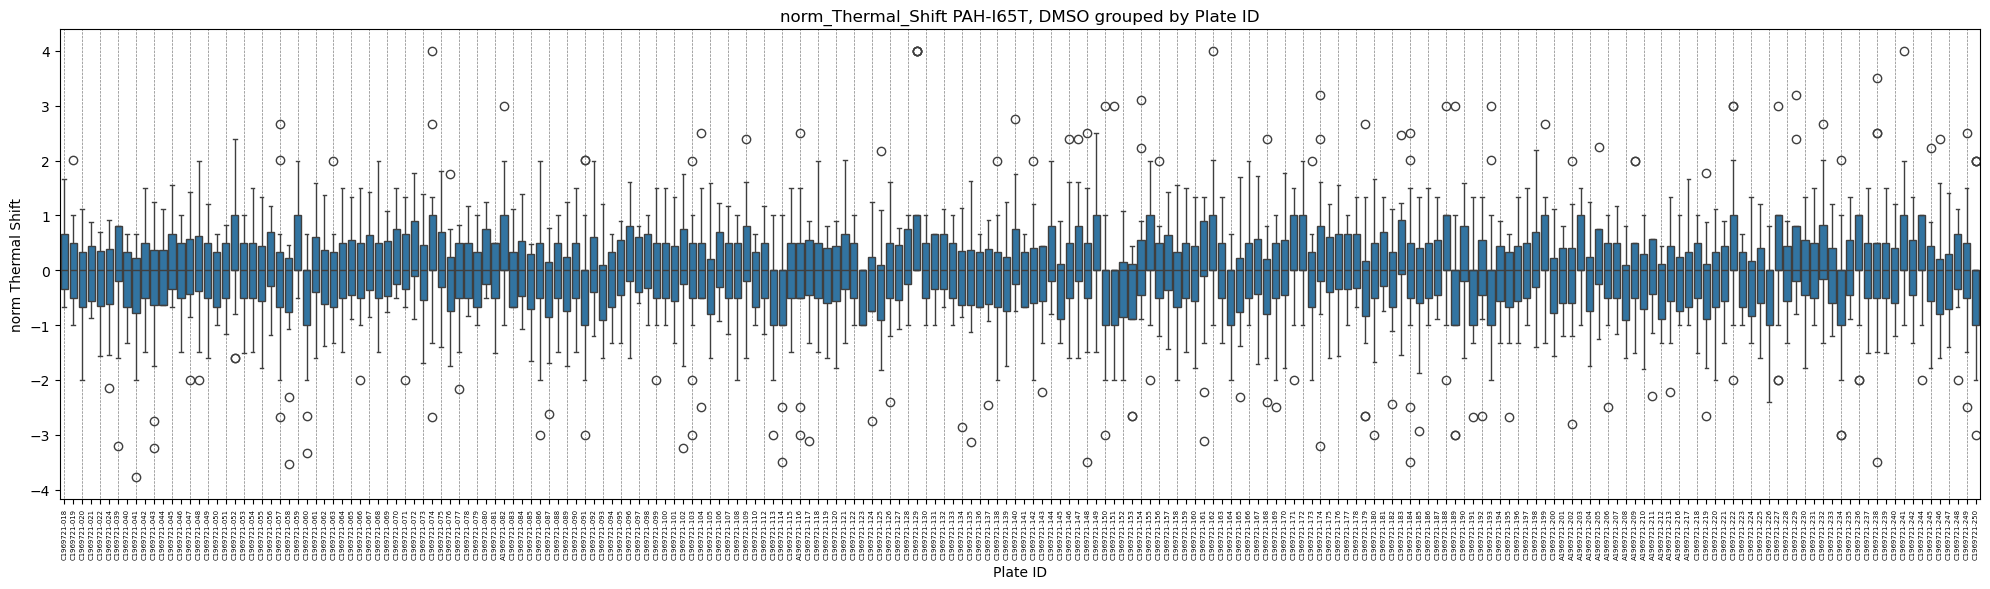

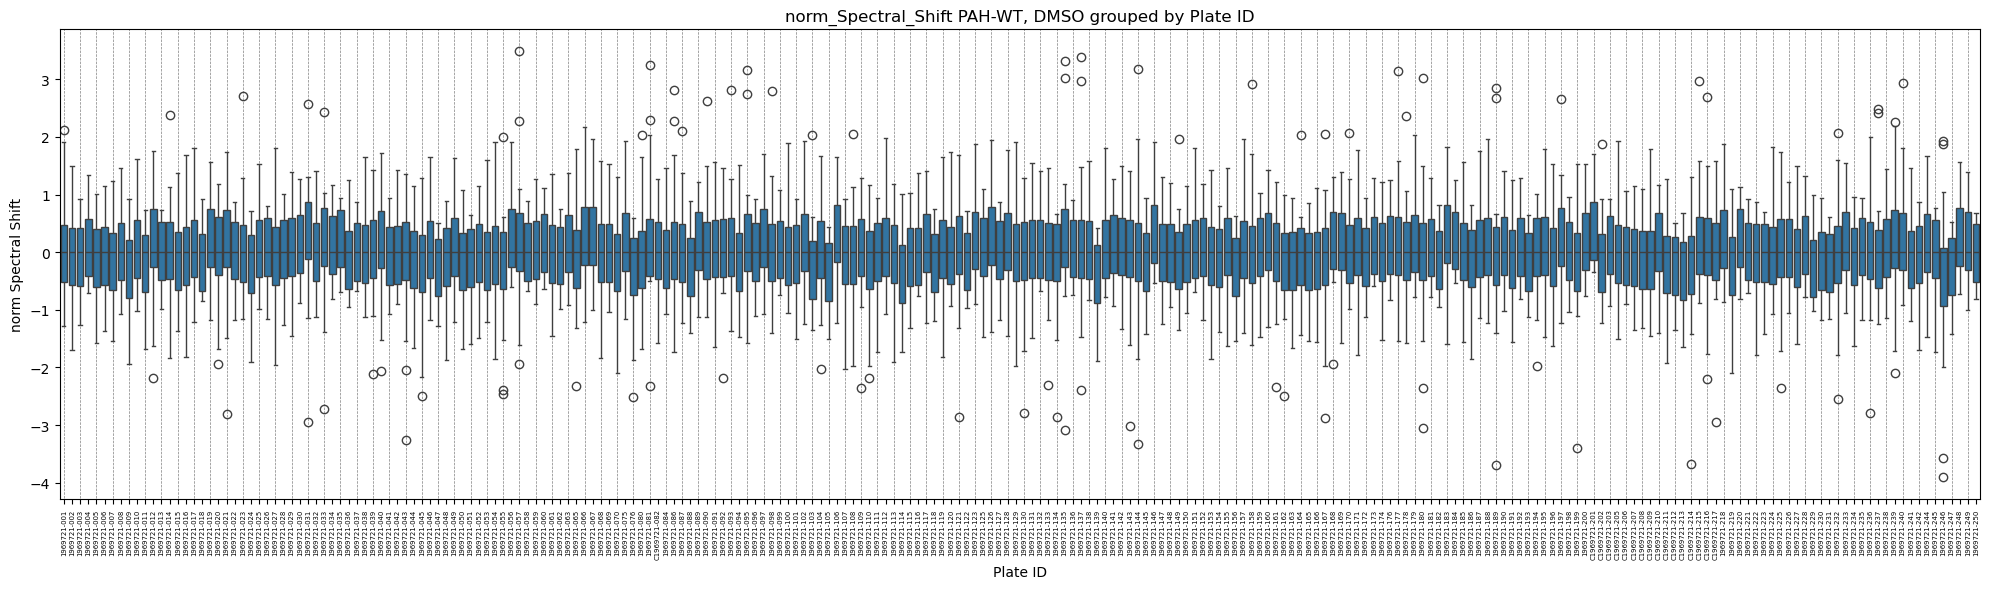

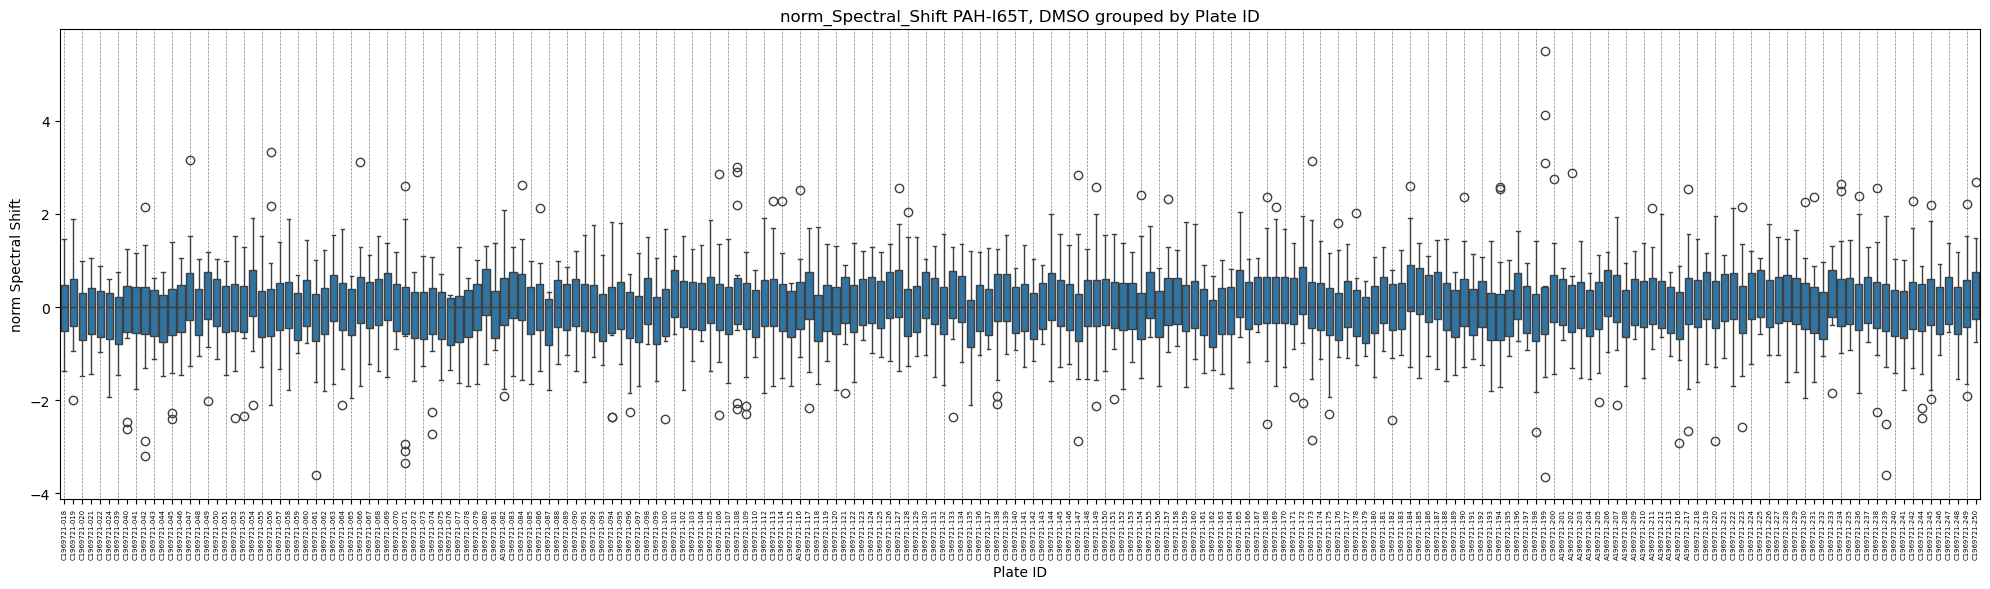

In [27]:
# Plot Delta values DMSO

boxplot_per_plate(df_ctrl, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  #ylim=[-2,2]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  #ylim=[-2,2]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  #ylim=[-.5,.5]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  #ylim=[-.5,.5]
                 )

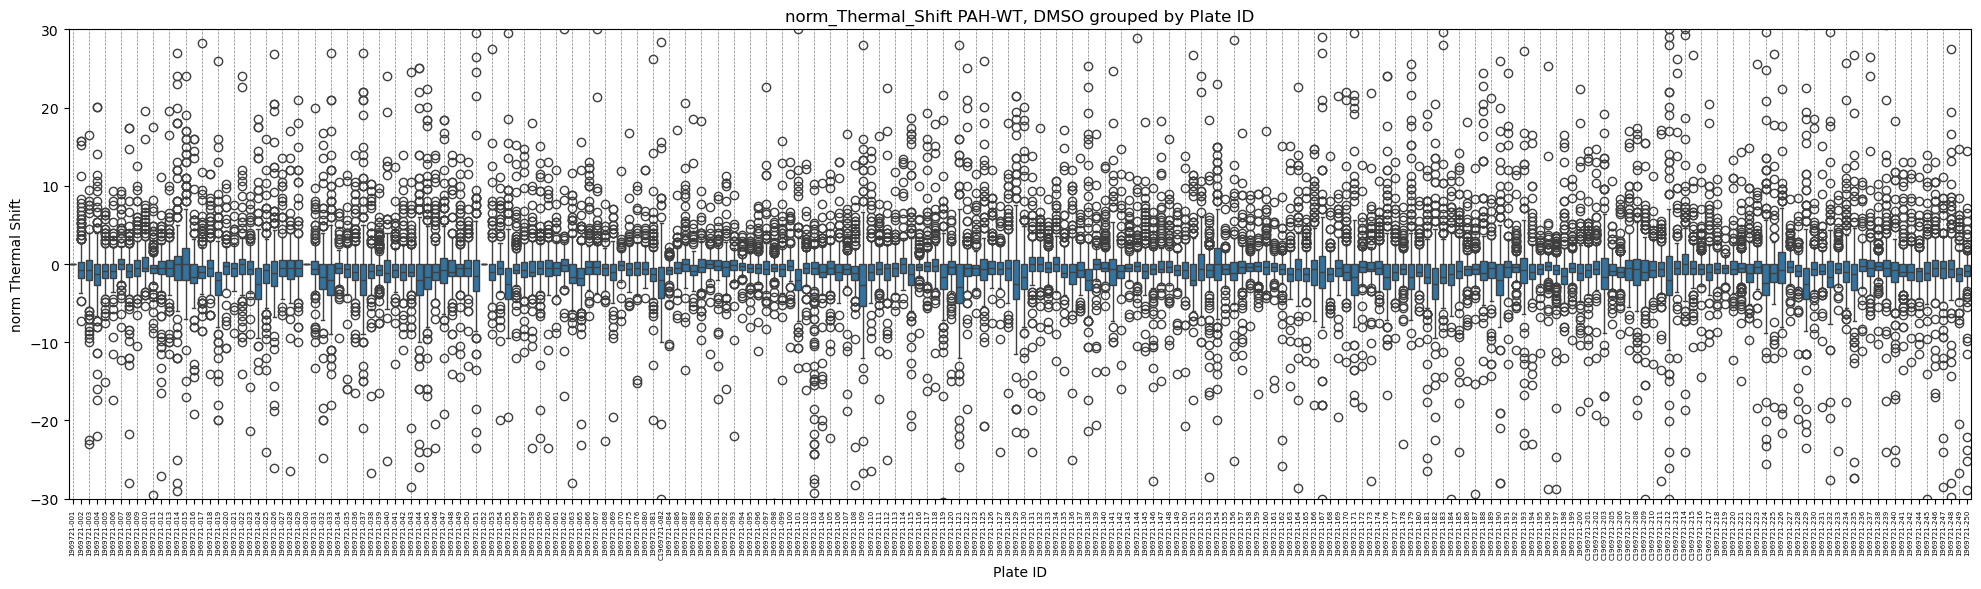

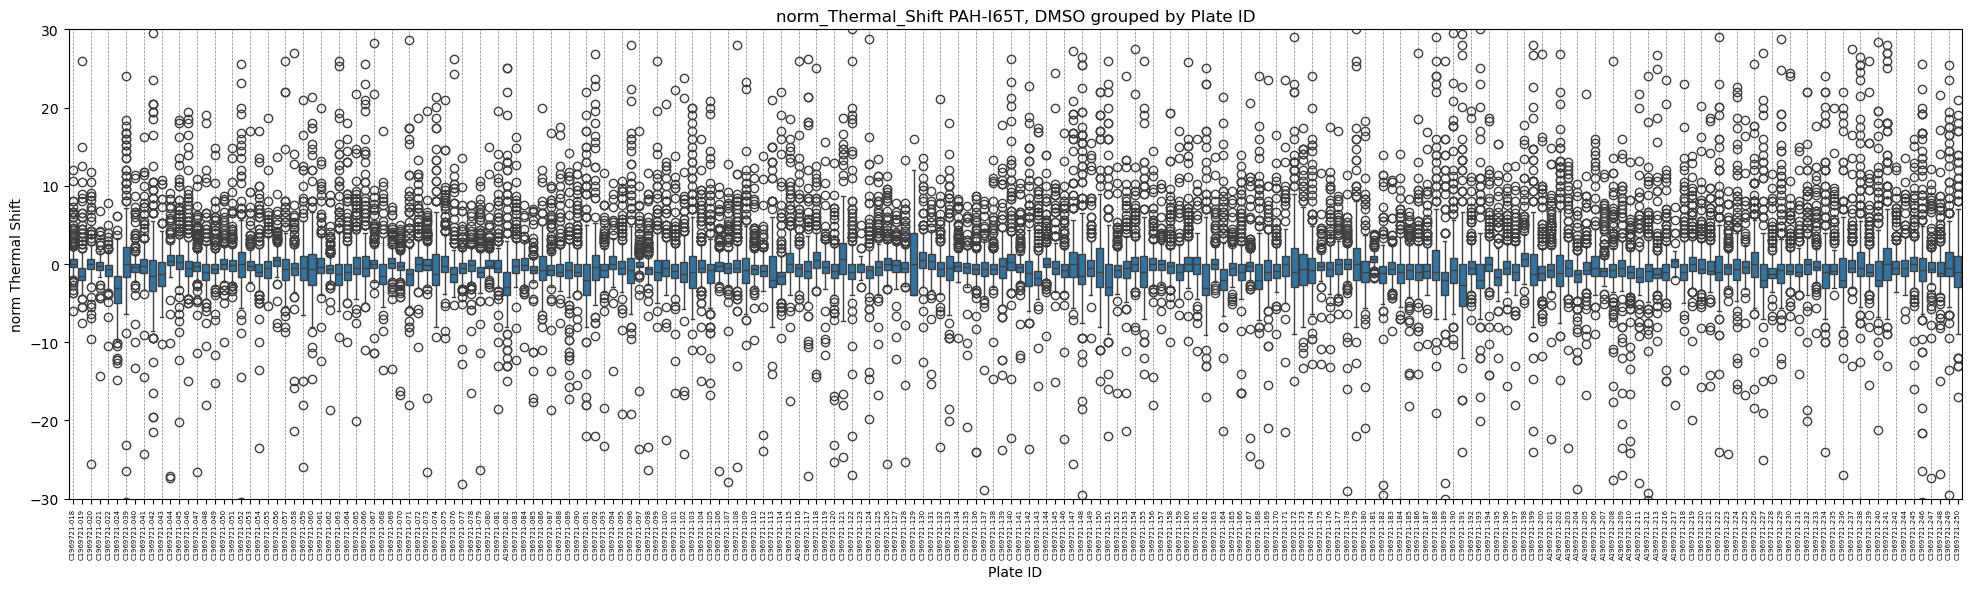

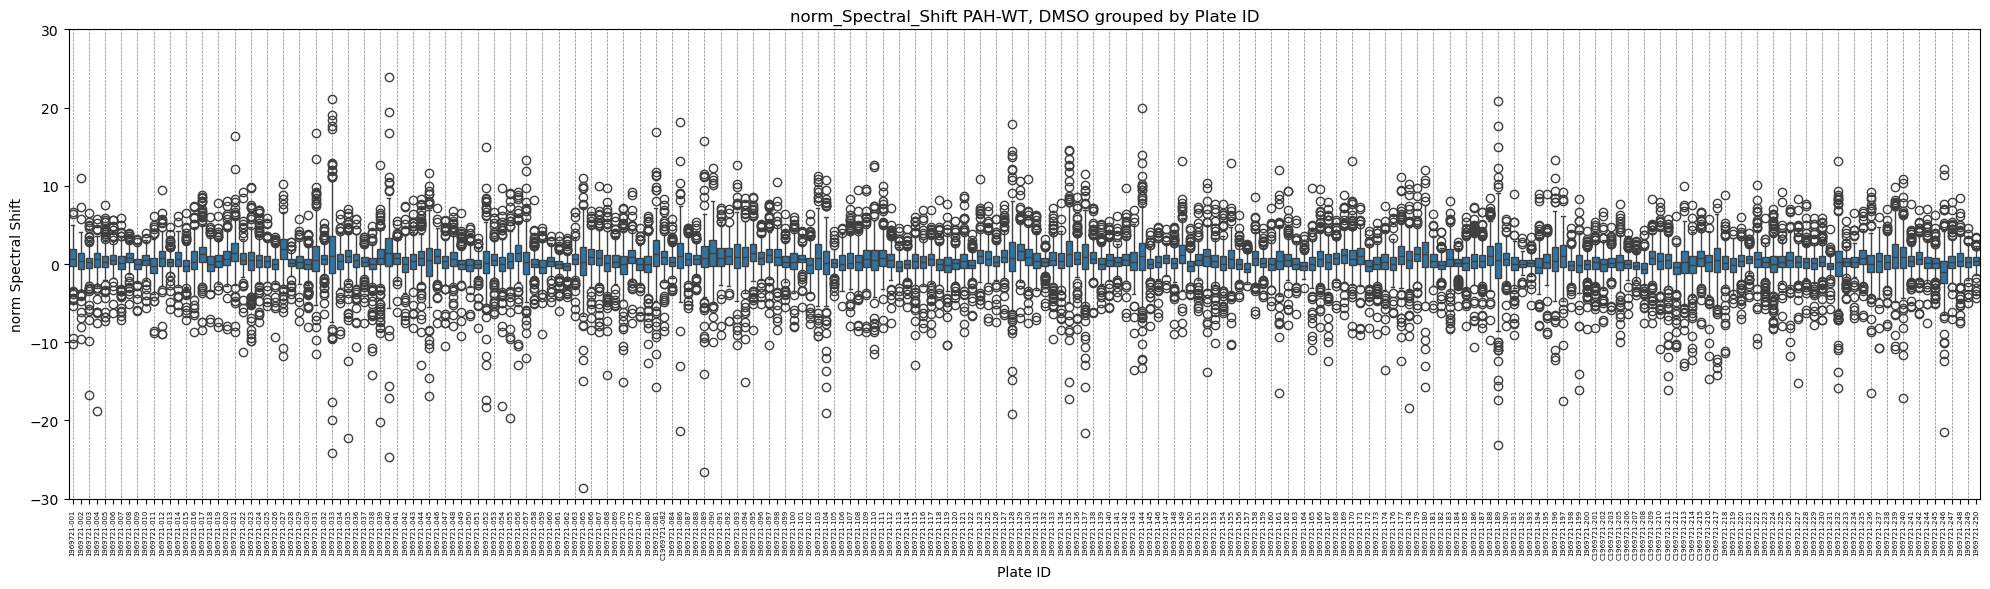

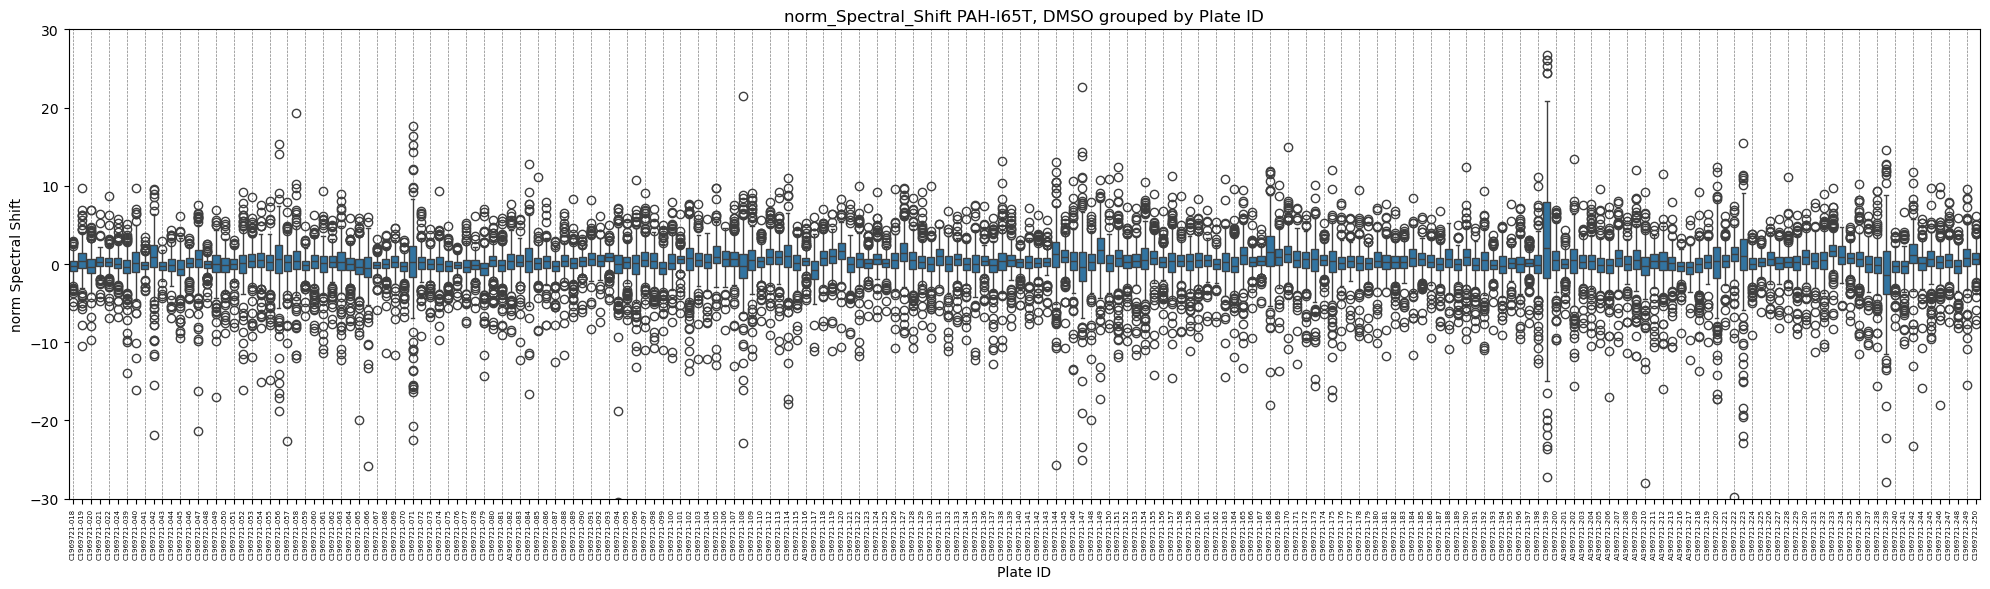

In [28]:
# Plot Delta values other

boxplot_per_plate(df_other, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-30, 30]
                 )

boxplot_per_plate(df_other, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-30, 30]
                 )

boxplot_per_plate(df_other, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-30, 30]
                 )

boxplot_per_plate(df_other, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-30, 30]
                 )

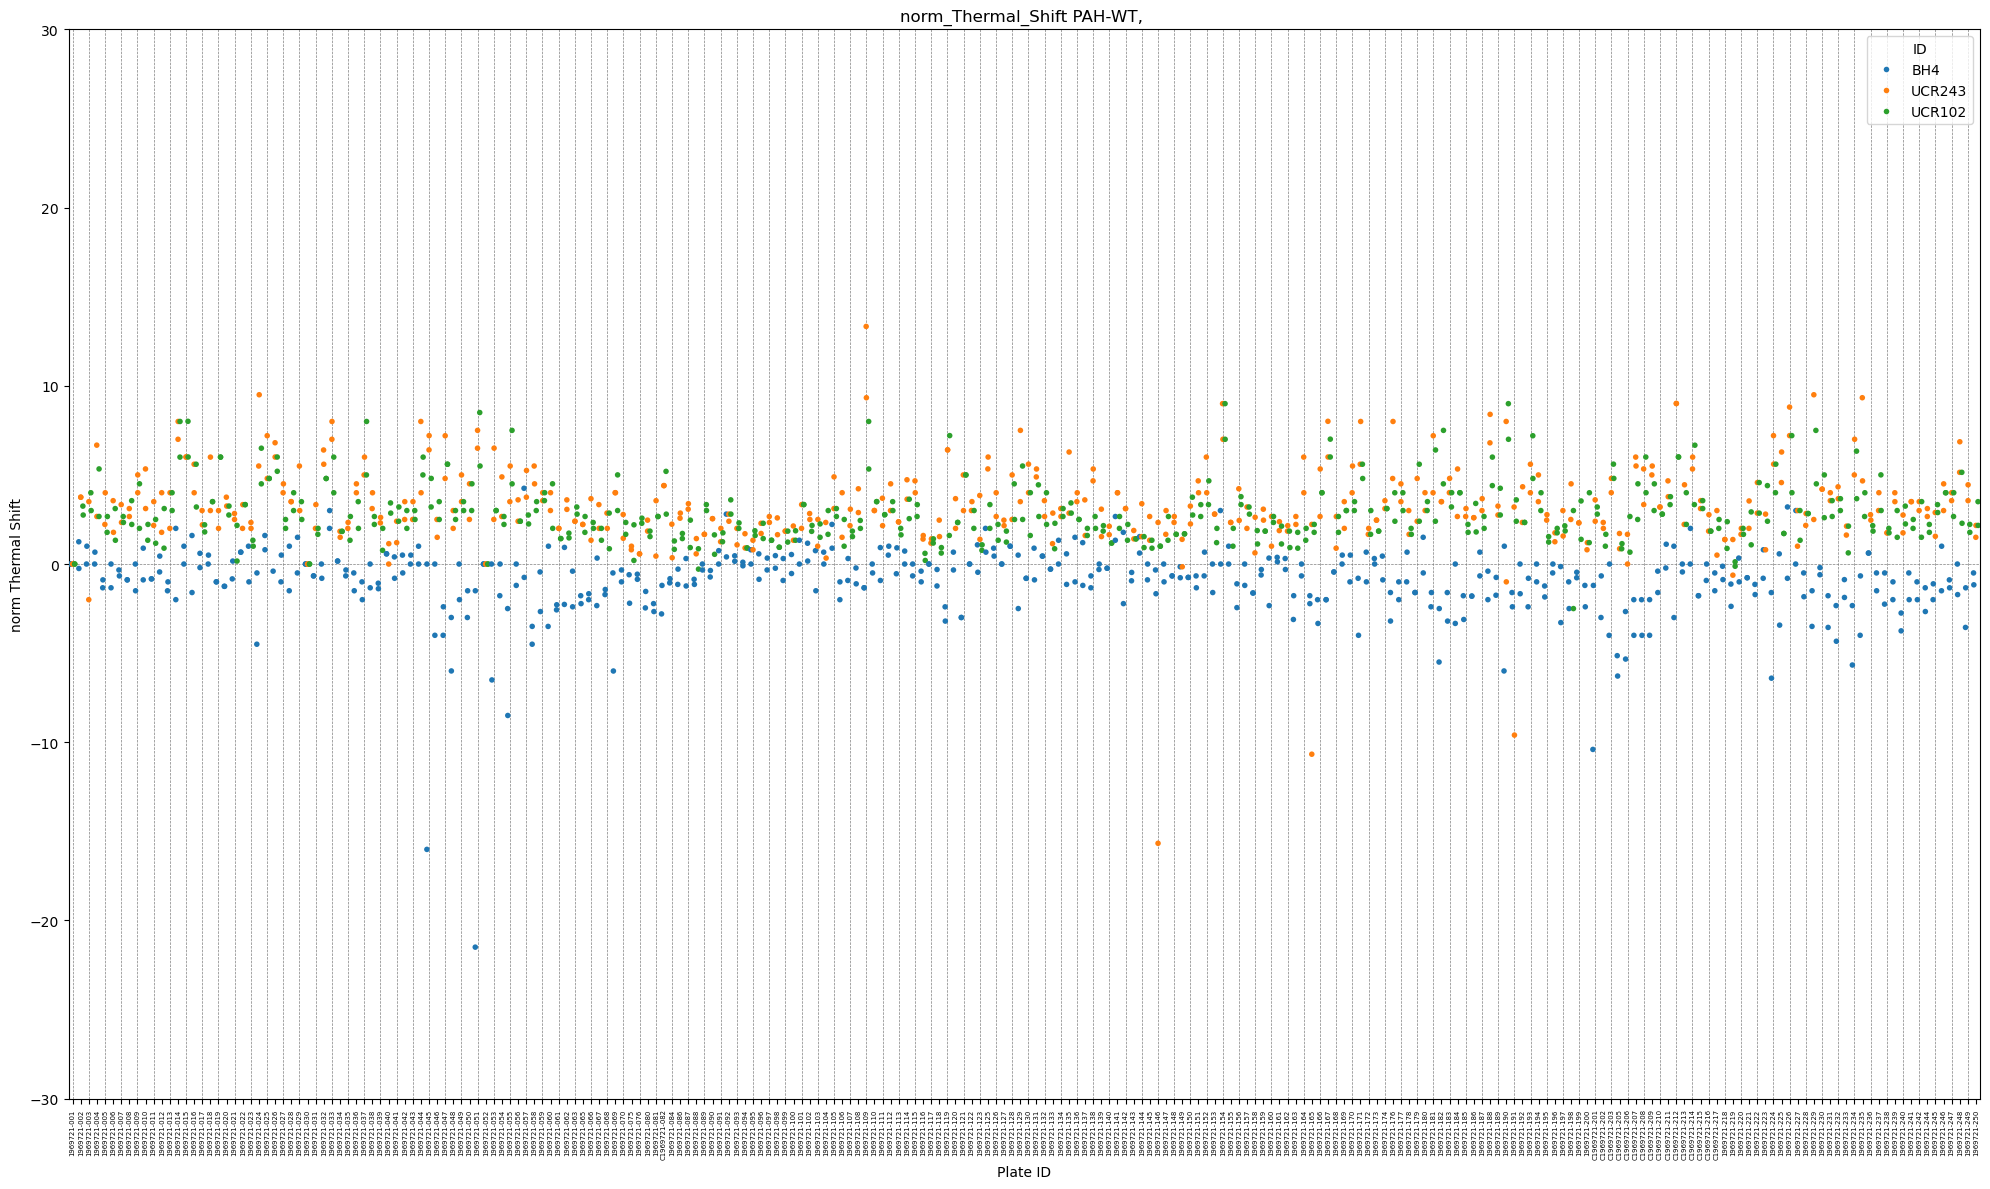

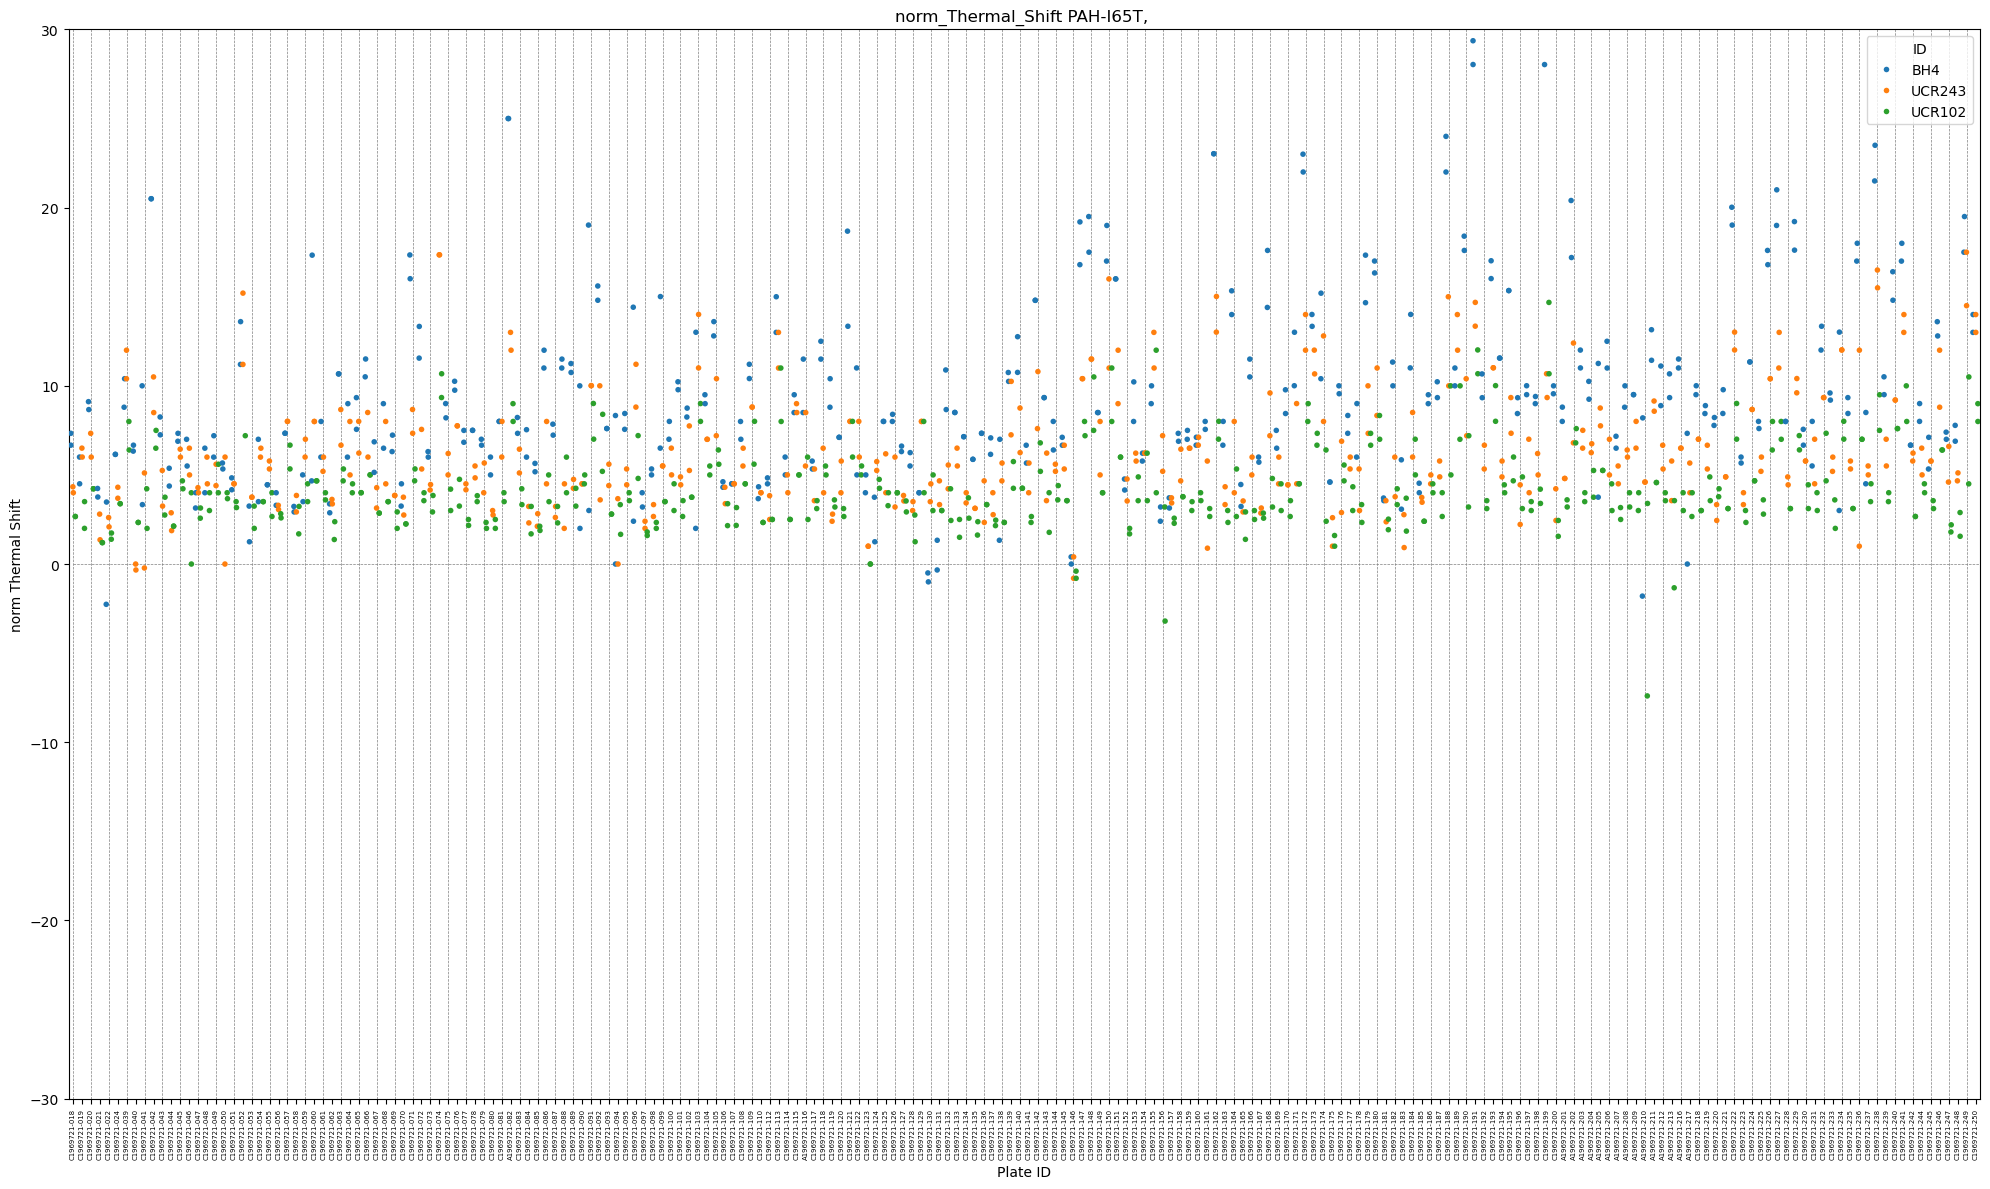

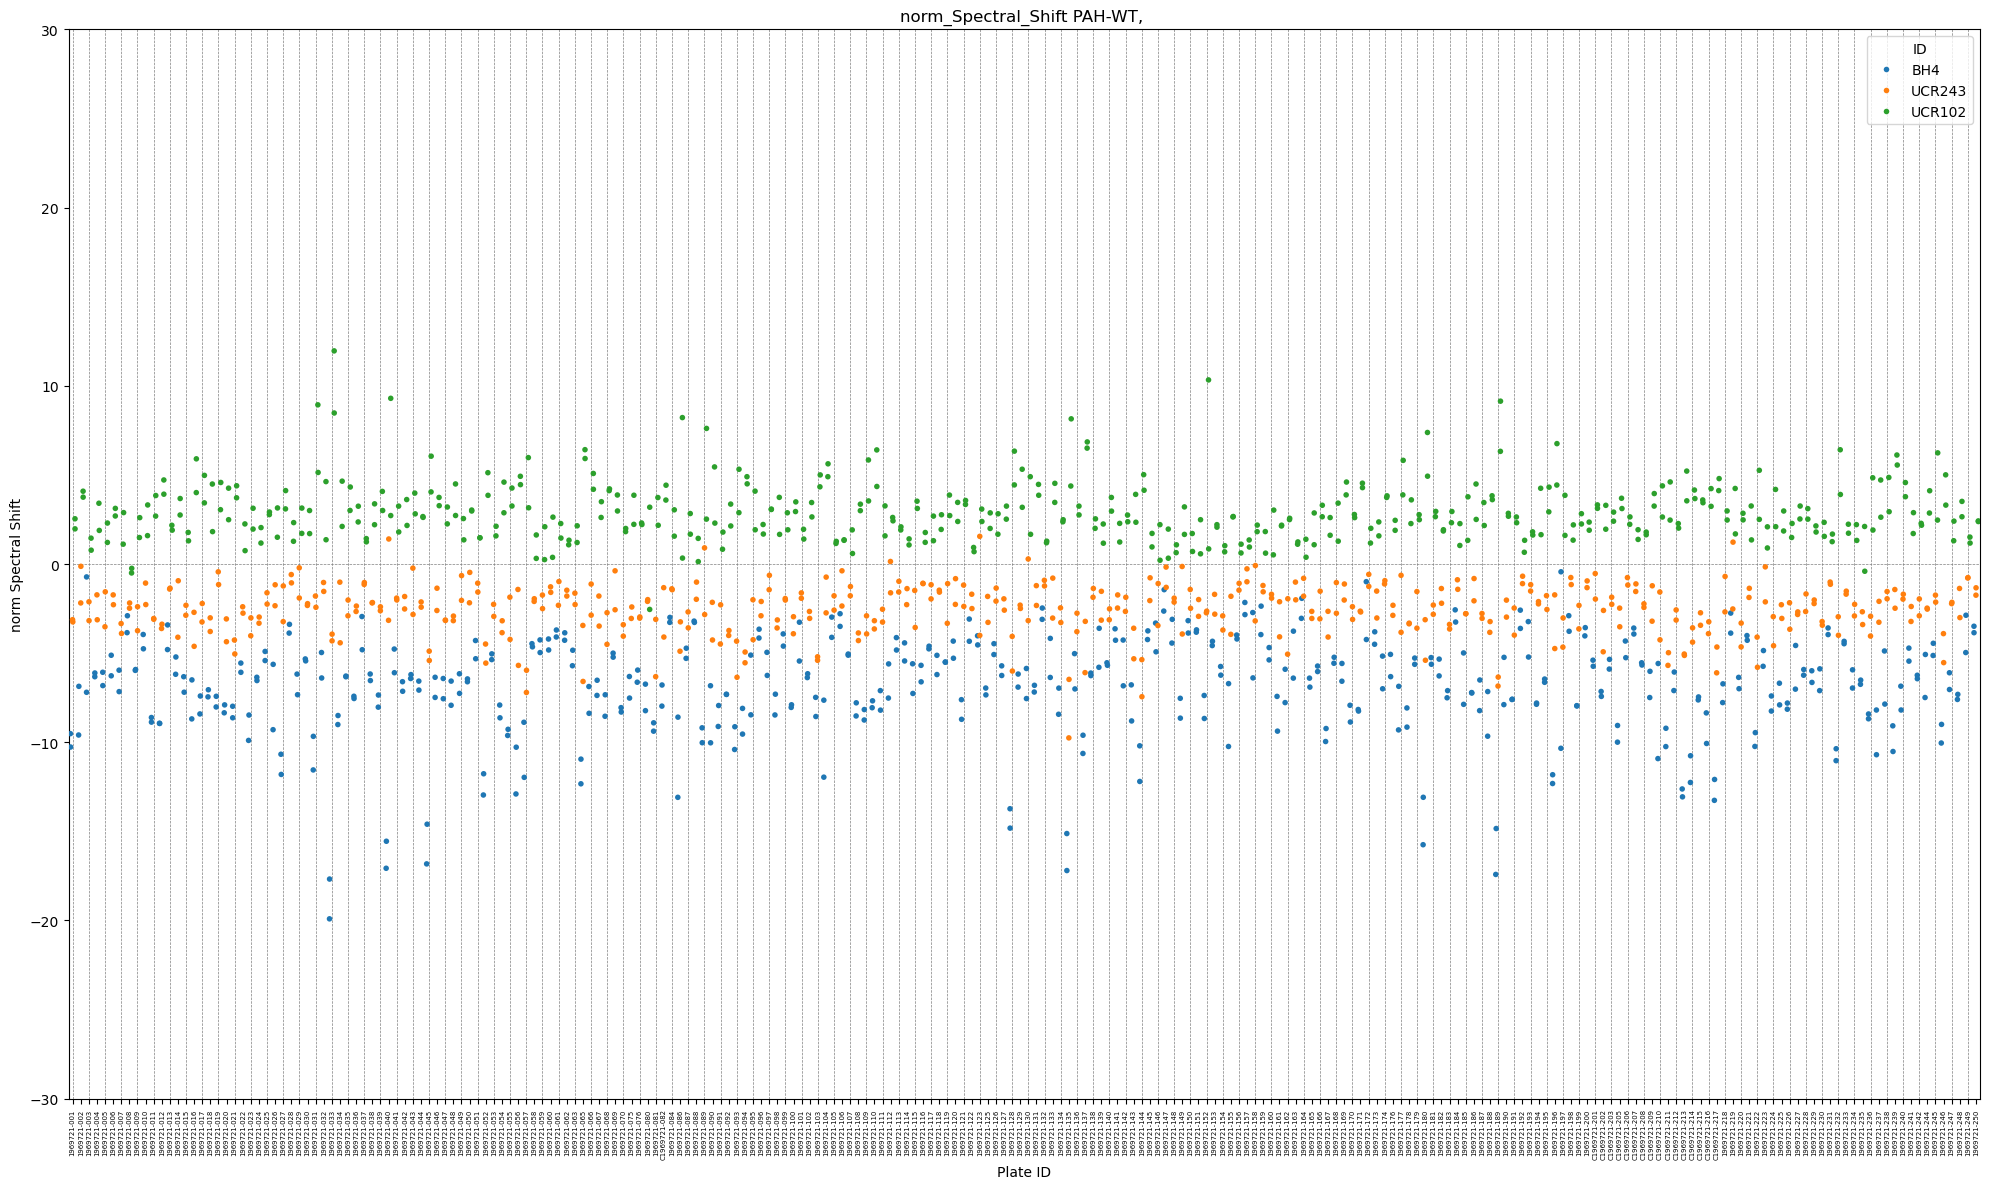

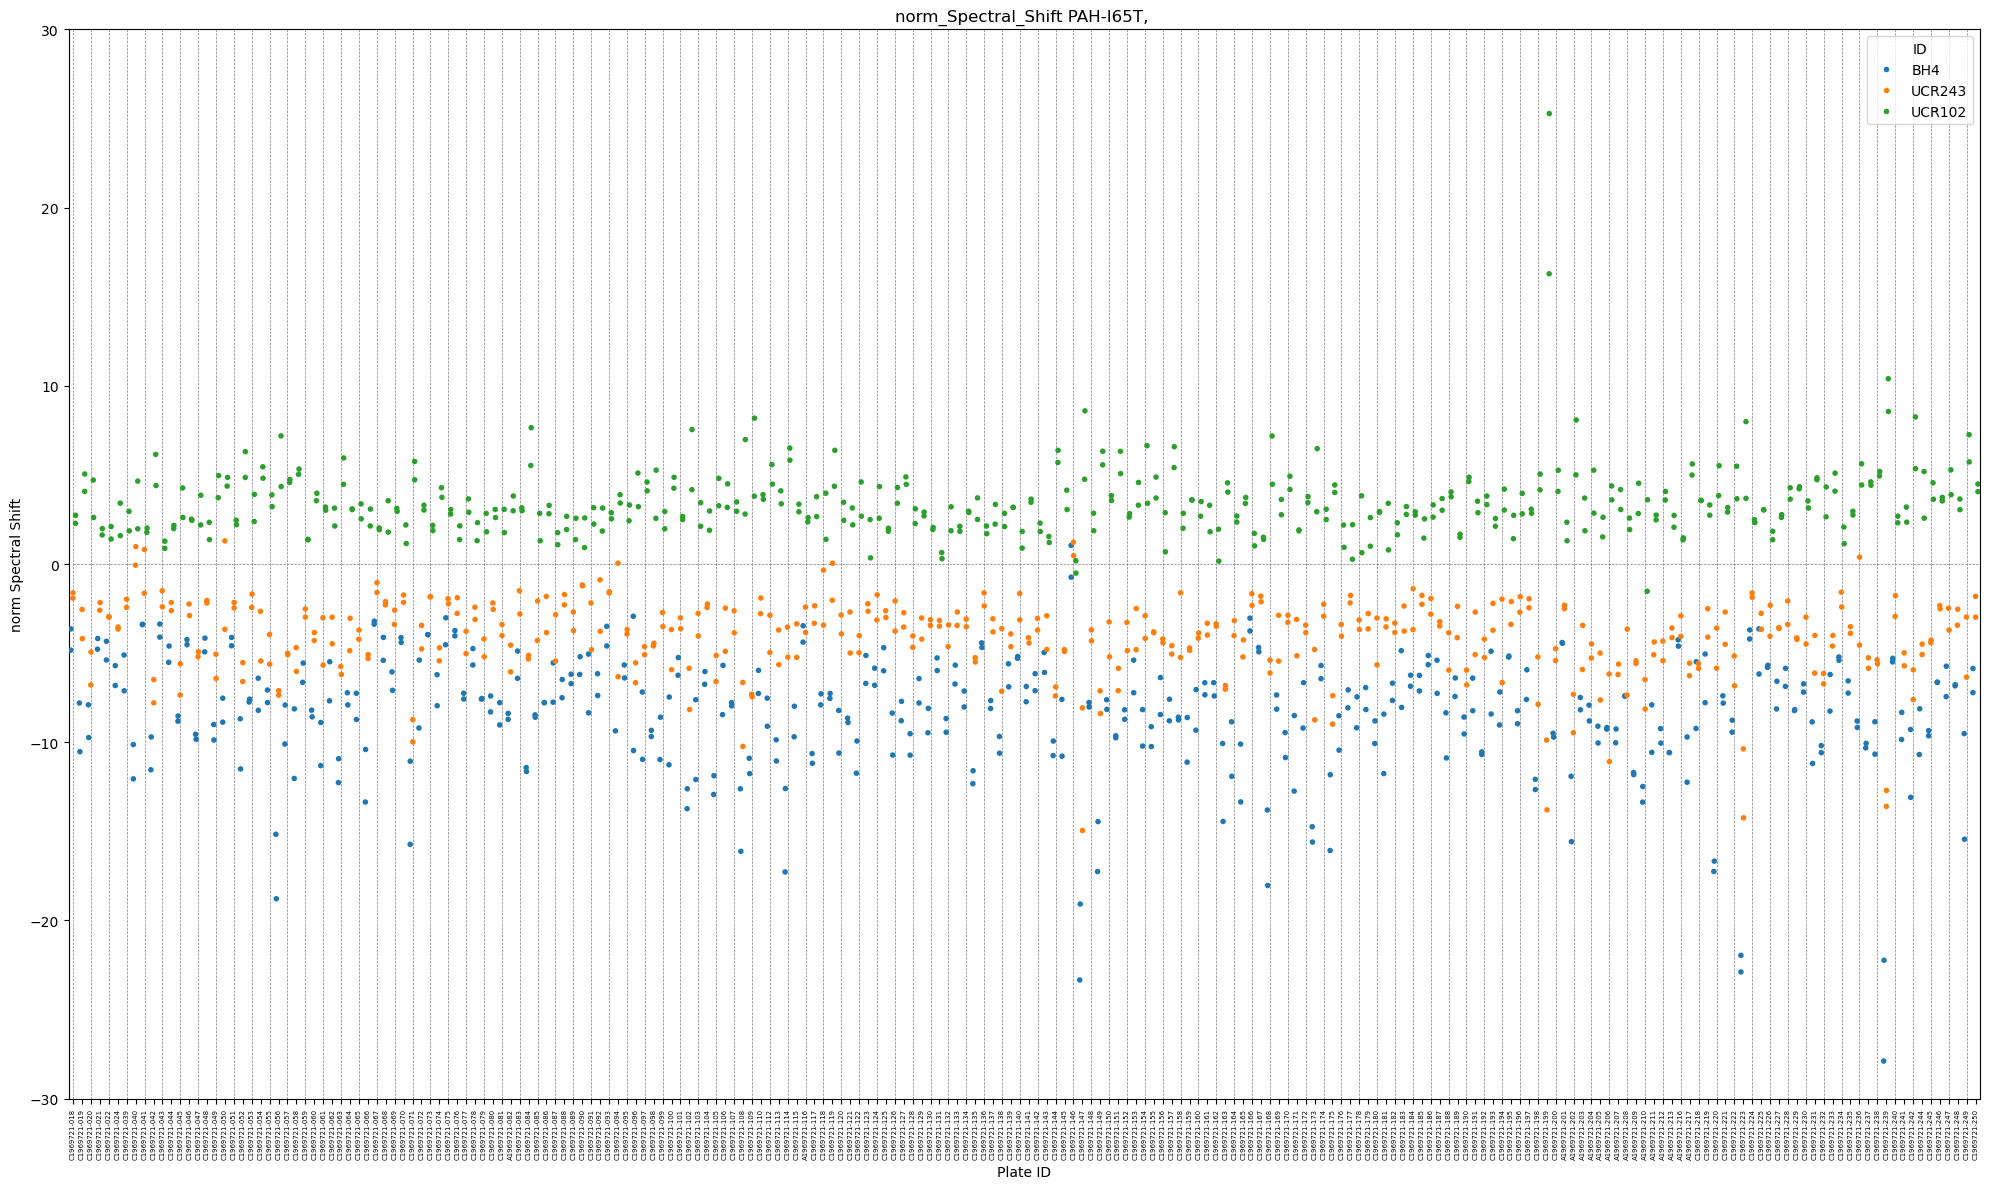

In [49]:
# Plot positive controls

dotplot_per_plate(df_other, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-WT', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-30, 30]
                 )

dotplot_per_plate(df_other, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-30, 30]
                 )

dotplot_per_plate(df_other, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-WT', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-30, 30]
                 )

dotplot_per_plate(df_other, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-30, 30]
                 )

In [31]:
# Complete the QC table by adding the distribuation of positive controls
df_qc_outlier_removed = df_qc.loc[df_qc['out_of_distribution'] == 'no']

df_qc_new = {}
th_set_2 = {}
for protein in ['PAH-WT', 'PAH-I65T']:
    df_qc_prot = df_qc_outlier_removed.loc[df_qc_outlier_removed['Protein'] == protein].copy()
    for pos_ctrl in ['BH4', 'UCR243', 'UCR102']:
        for assay in ['norm_Thermal_Shift', 'norm_Spectral_Shift']:
            df_qc_, [thr_min, thr_max] = pos_ctrl_qc(df_other, protein, pos_ctrl, assay)
            df_qc_prot = pd.merge(df_qc_prot, df_qc_, left_index=True, right_index=True, how='outer')
            th_set_2[f'{protein}_{pos_ctrl}_{assay}'] = [thr_min, thr_max]
            
    df_qc_new[protein] = df_qc_prot
df_qc_new = pd.concat(list(df_qc_new.values()))

df_qc_new.head()

,Protein,TSA_median,TSA_iqr,SpSh_median,SpSh_iqr,fl25_median,fl25_iqr,out_of_distribution,abnormal_BH4_norm_Thermal_Shift,abnormal_BH4_norm_Spectral_Shift,abnormal_UCR243_norm_Thermal_Shift,abnormal_UCR243_norm_Spectral_Shift,abnormal_UCR102_norm_Thermal_Shift,abnormal_UCR102_norm_Spectral_Shift
1969721-001,PAH-WT,49.4840,0.00000,2.903465,0.031402,-32414.554826,2734.591900,no,0.0,0.0,0.0,0.0,0.0,0.0
1969721-002,PAH-WT,49.3487,0.18040,3.001054,0.034008,-27865.316910,1905.986941,no,0.0,0.0,0.0,0.0,0.0,0.0
1969721-003,PAH-WT,49.2134,0.18040,2.976828,0.049121,-29299.307264,2267.008084,no,0.0,0.0,1.0,0.0,0.0,0.0
1969721-004,PAH-WT,49.4840,0.13520,2.972701,0.043583,-30133.408495,2838.254957,no,0.0,0.0,0.0,0.0,0.0,0.0
1969721-005,PAH-WT,49.3036,0.20295,2.897231,0.044305,-31840.723069,1322.385006,no,0.0,0.0,0.0,0.0,0.0,0.0


In [32]:
df_qc_new.loc['C1969721-205']

Protein                                      PAH-WT
TSA_median                                  48.8527
TSA_iqr                                    0.315675
SpSh_median                                2.981141
SpSh_iqr                                   0.032759
fl25_median                           -23093.025058
fl25_iqr                                2081.497476
out_of_distribution                              no
abnormal_BH4_norm_Thermal_Shift                 2.0
abnormal_BH4_norm_Spectral_Shift                0.0
abnormal_UCR243_norm_Thermal_Shift              0.0
abnormal_UCR243_norm_Spectral_Shift             0.0
abnormal_UCR102_norm_Thermal_Shift              0.0
abnormal_UCR102_norm_Spectral_Shift             0.0
Name: C1969721-205, dtype: object

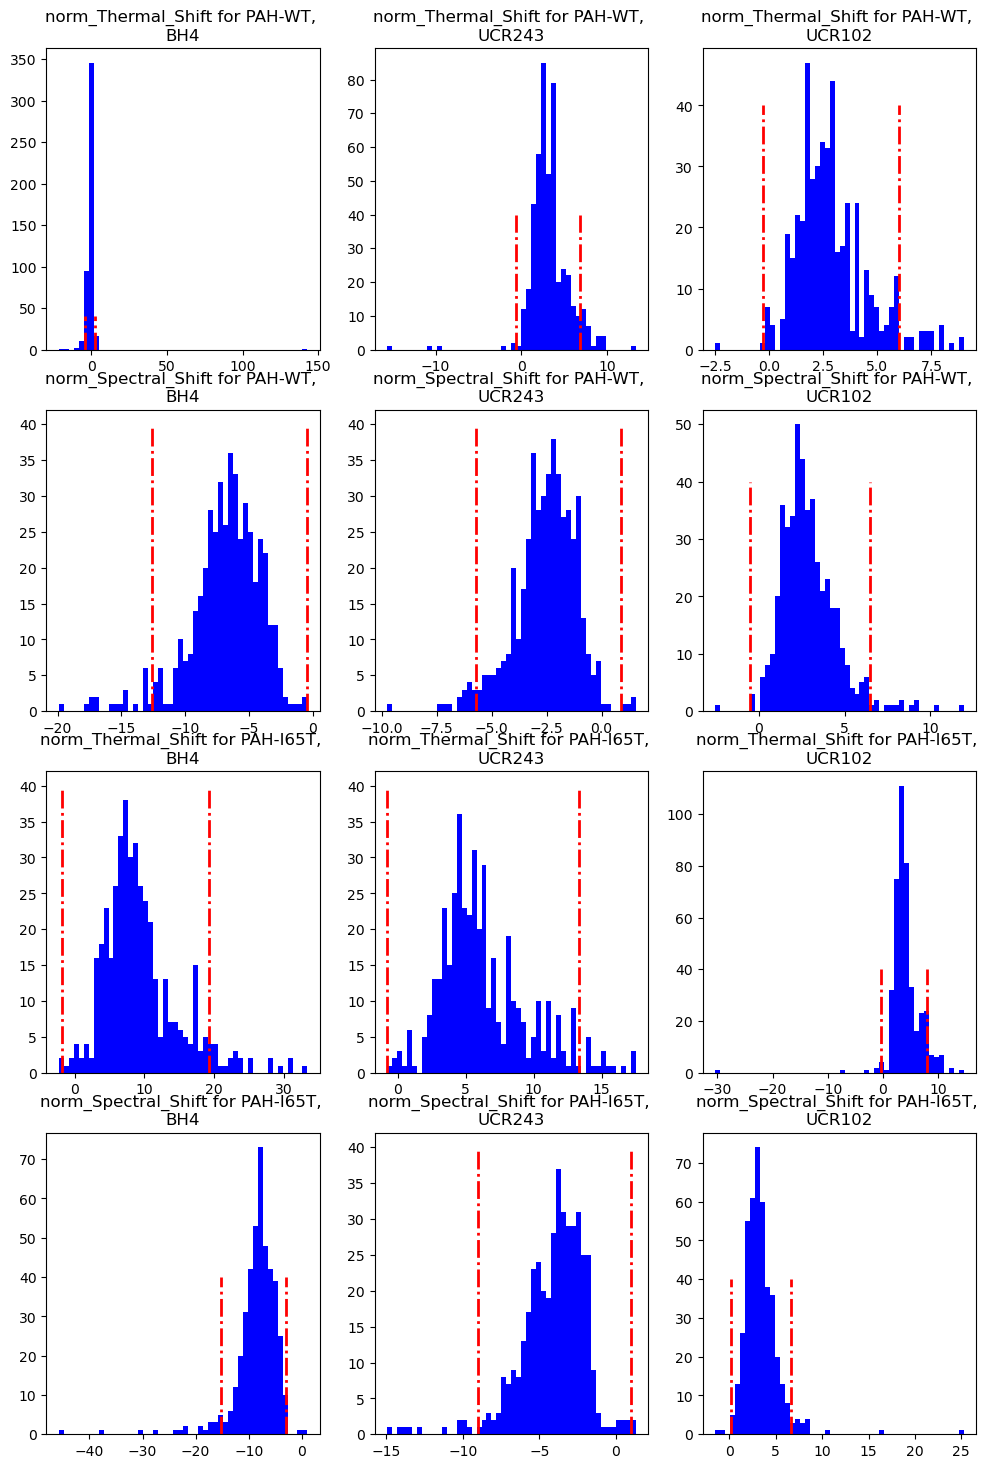

In [33]:
# ditribution of pos control with thershold
fig, ax = plt.subplots(4, 3, figsize=(12, 18))
ax = ax.flatten()

i = 0
for protein in ['PAH-WT', 'PAH-I65T']:
    df_qc_prot = df_other.loc[df_other['Protein'] == protein].copy()
    for assay in ['norm_Thermal_Shift', 'norm_Spectral_Shift']:
        for pos_ctrl in ['BH4', 'UCR243', 'UCR102']:
            df_qc_prot_ctrl = df_qc_prot.loc[df_qc_prot['ID'] == pos_ctrl].copy()
            
            ax[i].hist(df_qc_prot_ctrl[assay], 50, color='blue');
            ax[i].vlines(th_set_2[f'{protein}_{pos_ctrl}_{assay}'], ymin=0, ymax=40, colors='red', linestyles='-.', linewidth=2)
            ax[i].set_title(f'{assay} for {protein}, \n{pos_ctrl}');
            i += 1

In [34]:
sum_abnormal_all_pos_ctrls = np.array(df_qc_new.iloc[:,8:]).sum(1)
sum_abnormal_UCRs = np.array(df_qc_new.iloc[:,10:]).sum(1)

df_qc_new['sum_abnormal_all_pos_ctrls'] = sum_abnormal_all_pos_ctrls
df_qc_new['sum_abnormal_UCRs'] = sum_abnormal_UCRs

In [35]:
df_qc_new['sum_abnormal_all_pos_ctrls'].value_counts().sort_index()

sum_abnormal_all_pos_ctrls
0.0     329
1.0      65
2.0      25
3.0      11
4.0       7
5.0       8
6.0       3
7.0       1
10.0      1
Name: count, dtype: int64

In [36]:
df_qc_new['sum_abnormal_UCRs'].value_counts().sort_index()

sum_abnormal_UCRs
0.0    353
1.0     59
2.0     22
3.0      9
4.0      6
6.0      1
Name: count, dtype: int64

In [37]:
# Are all nan values are those that are out of distriubution? yes

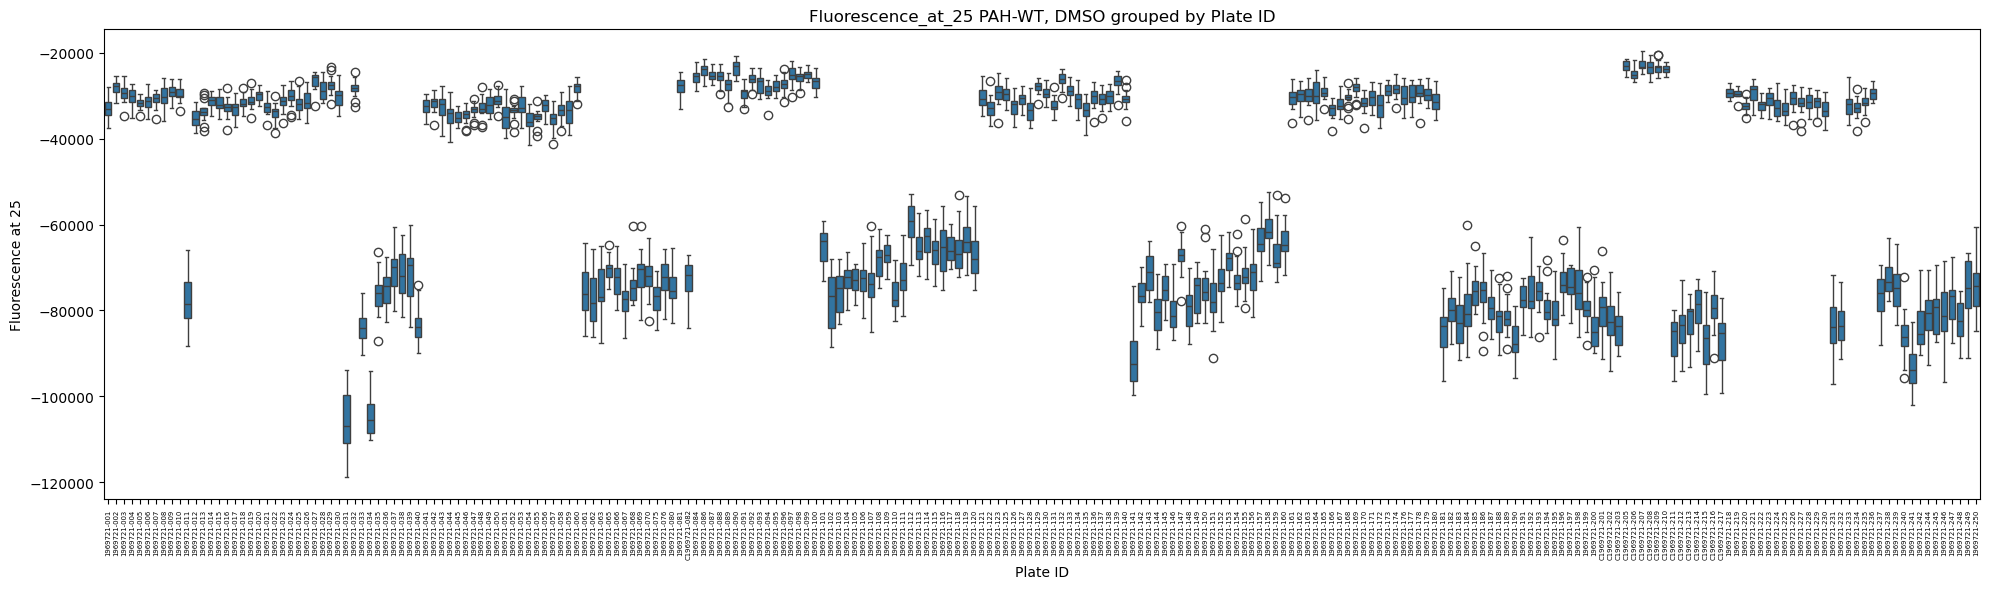

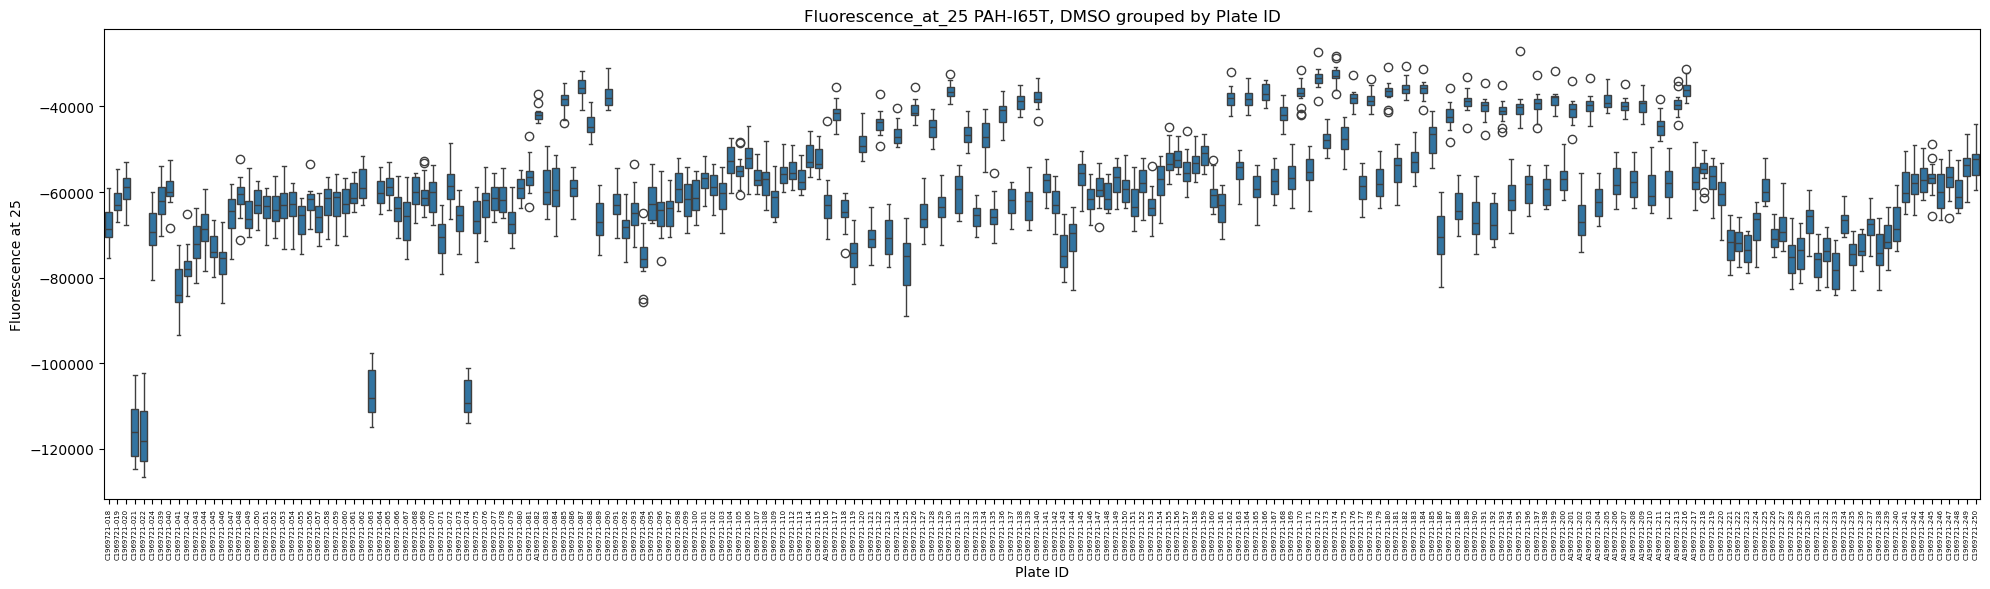

In [38]:
boxplot_per_plate(df_ctrl, 
                  assay = 'Fluorescence_at_25', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Fluorescence_at_25', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

In [39]:
# Save
save_tag = '23jul'
print(save_tag)
df_other.to_csv(f"data/PO_processed_{save_tag}_batch_effect_remove.csv")
df_ctrl.to_csv(f"data/PO_processed_dmso_{save_tag}_batch_effect_remove.csv")
df_qc_new.to_csv(f"data/qc_table_alpha_01_bonf_{save_tag}_batch_effect_remove.csv")

23jul


In [22]:
with open("outlire_plate_italo.txt", 'r') as file:
    plate_set_italo = file.read()
plate_set_italo = plate_set_italo.split('\n')
len(plate_set_italo)

35

In [27]:
len(set(plate_outlier).intersection(set(plate_set_italo)))

12

In [30]:
len(set(plate_set_italo) - set(plate_outlier))

23

In [28]:
# plate_set_italo is only calculated based on SD and 1.5IQR method resulting on 35 plates.
# There are 12 plates that we als remove remaining with 23.

# Accordingly, even if there is only one outlier DMSO per palte, it sonsiders it as outlier

# Our mrthod replaces SD with IQR and also 3IQR to be less sensitive to a few DMSO outliers 
# Then we remove outlier DMSOs from the remaining plates.

# In addition, we also use median of DMOS plates.